# Bank Term Deposit Subscription Prediction

## Project goals and success criteria

- **Goal:** Predict whether a customer subscribes to a term deposit: `y = yes (1)` or `no (0)`.
- **Success metric:** Achieve **at least 81% mean accuracy across 5-fold cross-validation**, and report the average score and fold variability.
- **Business questions:** Which customer segments should the client prioritize? Which features best predict subscription?
- **Business evaluation:** Also report class 1 F1, recall and call-prioritization lift because subscribers are a small minority.

## 0. Install packages if needed


In [31]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn imbalanced-learn joblib ipython

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and configuration

In [32]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.combine import SMOTETomek

RANDOM_STATE = 42
DATA_FILE_PATH = Path("bank.csv") 
RESULTS_DIRECTORY = Path("bank_results")
RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)
TEST_SIZE = 0.20
CYCLICAL_MONTH = True
RUN_TUNING = False  # Set True for the optional, slower hyperparameter search.
SEARCH_ITERATIONS = 12
MIN_ACCURACY = 0.81
THRESHOLD_GOAL = "f1"  # Choose "f1" or "precision".
TARGET_PRECISION = 0.40
DROP_EXACT_DUPLICATES = False  # Identical rows are not necessarily the same customer.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# GridSearchCV is nested inside each outer validation fold for the three variants.
LOGISTIC_C_VALUES = np.logspace(-3, 3, 5)
LOGISTIC_C_VALUES = [0.01, 0.1, 1.0]
LOGISTIC_GRID_FOLDS = 2
LOGISTIC_GRID_SCORING = "f1"  # Change to "f1" if F1 at 0.5 is your objective.


## 2. Read and check the original dataset
CSV separator is detected automatically. In Colab, upload your file using the Files panel, then set `DATA_FILE_PATH`. The target must be named `subscription_labels` and contain yes/no or 0/1.

In [33]:
# Load the customer happiness survey dataset
DATA_FILE_PATH = Path("C:\\Users\\Anagha\\OneDrive\\Apziva\\APzivaP2_BankingPredictionSubsription\\ApzivaP2_Data\\term-deposit-marketing-2020.csv")

In [34]:
if not DATA_FILE_PATH.exists():
    raise FileNotFoundError(f"Upload your bank CSV and set DATA_PATH. Not found: {DATA_FILE_PATH}")
bank_data = pd.read_csv(DATA_FILE_PATH, sep=None, engine="python")
bank_data.columns = bank_data.columns.str.strip().str.lower()

# Remove accidental CSV index columns, not customer features.
bank_data = bank_data.loc[:, ~bank_data.columns.str.startswith("unnamed:")].copy()
if bank_data.columns.duplicated().any():
    raise ValueError("Duplicate column names detected. Check the CSV header.")
if "y" not in bank_data:
    raise ValueError("The dataset needs a target column named y.")
for column_name in bank_data.select_dtypes(include=["object", "string"]).columns:
    bank_data[column_name] = bank_data[column_name].astype(str).str.strip().str.lower()
    bank_data[column_name] = bank_data[column_name].replace({"": np.nan, "nan": np.nan, "none": np.nan})

# Convert labels explicitly; do not silently discard invalid target rows.
class_labels = bank_data["y"].astype(str).str.strip().str.lower()
subscription_labels = class_labels.map({"yes": 1, "no": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0})
if subscription_labels.isna().any():
    raise ValueError(f"Invalid or missing y labels: {class_labels[subscription_labels.isna()].unique()}")
bank_data["y"] = subscription_labels.astype(int)
print("Shape:", bank_data.shape)
print("Exact duplicate rows:", bank_data.duplicated().sum())
if DROP_EXACT_DUPLICATES:
    bank_data = bank_data.drop_duplicates().reset_index(drop=True)
display(bank_data.head())
display(pd.DataFrame({"dtype": bank_data.dtypes, "missing": bank_data.isna().sum()}))
display(bank_data["y"].value_counts().rename("customers"))

Shape: (40000, 14)
Exact duplicate rows: 0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,0


,dtype,missing
age,int64,0
job,object,0
marital,object,0
education,object,0
default,object,0
balance,int64,0
housing,object,0
loan,object,0
contact,object,0
day,int64,0


y
0    37104
1     2896
Name: customers, dtype: int64

## 3. Split before learning transformations or exploring outcomes
All detailed EDA below uses training rows. Keep the test set untouched until the final evaluation. Features must exclude the target and any identifiers. Duration is unavailable before a call and is removed by default.

In [35]:
customer_features = bank_data.drop(columns=["y", "duration"], errors="ignore")
subscription_labels = bank_data["y"]
training_customers_raw, test_customers_raw, training_labels, test_labels = train_test_split(
    customer_features, subscription_labels, test_size=TEST_SIZE, stratify=subscription_labels, random_state=RANDOM_STATE
)
# Reset indexes together so labels and customer rows remain aligned.
training_customers_raw = training_customers_raw.reset_index(drop=True)
test_customers_raw = test_customers_raw.reset_index(drop=True)
training_labels = training_labels.reset_index(drop=True)
test_labels = test_labels.reset_index(drop=True)
if training_labels.value_counts().reindex([0, 1], fill_value=0).min() < 5:
    raise ValueError("Each training class needs at least five rows for five-fold CV.")
training_eda = training_customers_raw.copy()
training_eda["y"] = training_labels
print("Training shape:", training_customers_raw.shape)
print("Test shape:", test_customers_raw.shape)
print("Training class counts:")
display(training_labels.value_counts())

Training shape: (32000, 12)
Test shape: (8000, 12)
Training class counts:


y
0    29683
1     2317
Name: count, dtype: int64

## 4. EDA: class imbalance and categorical counts

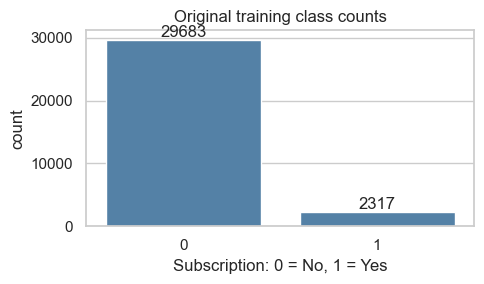

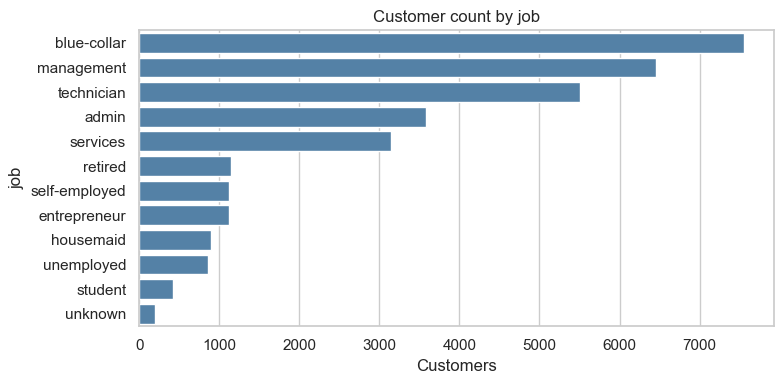

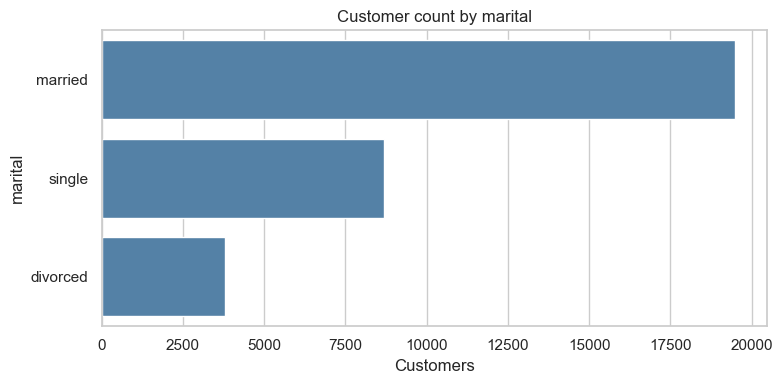

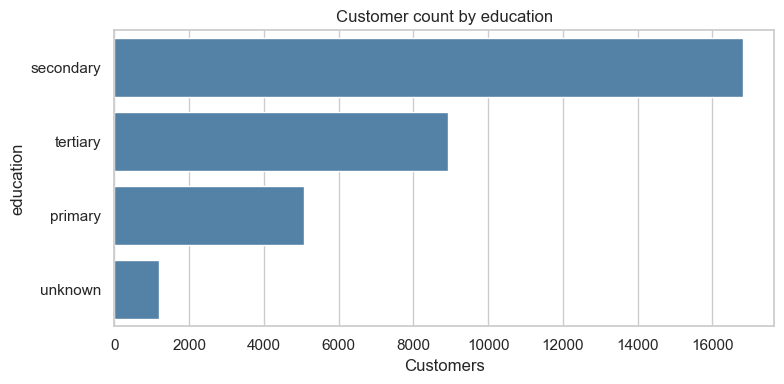

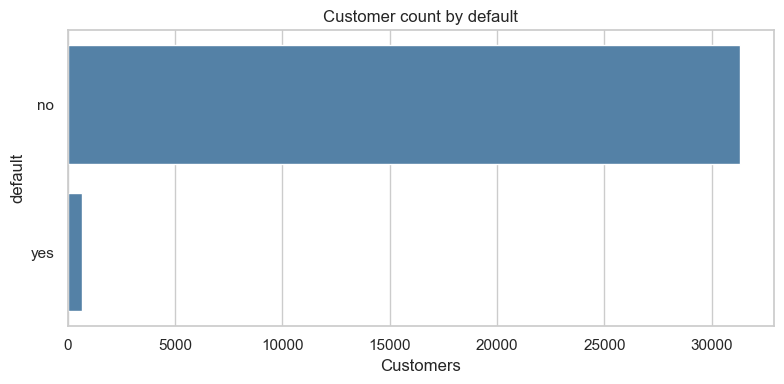

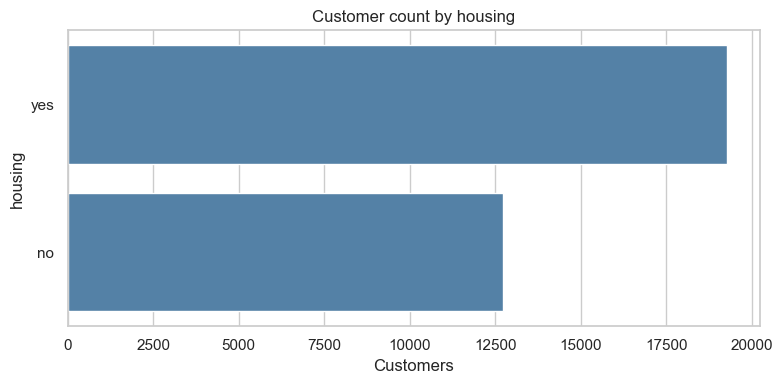

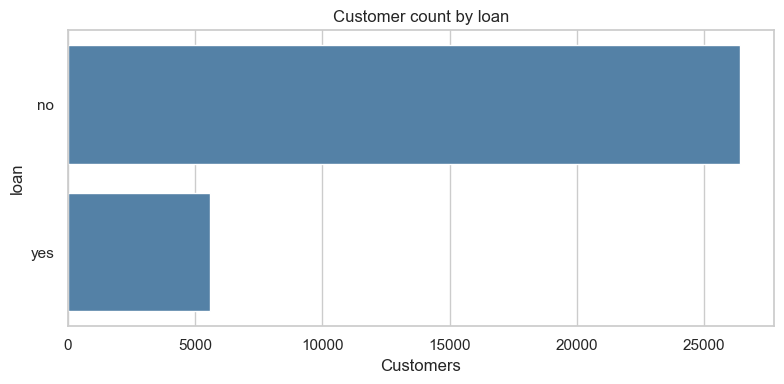

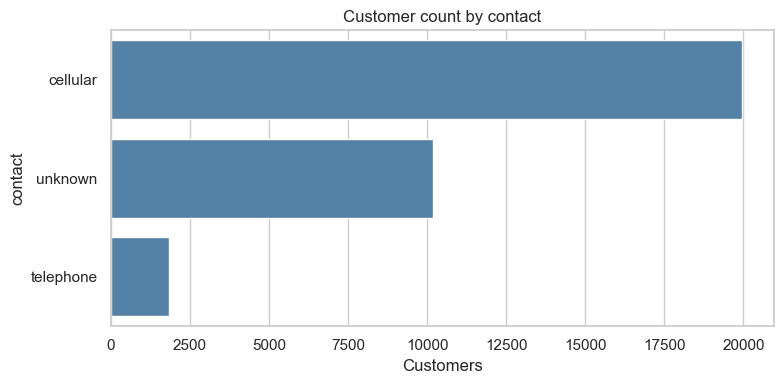

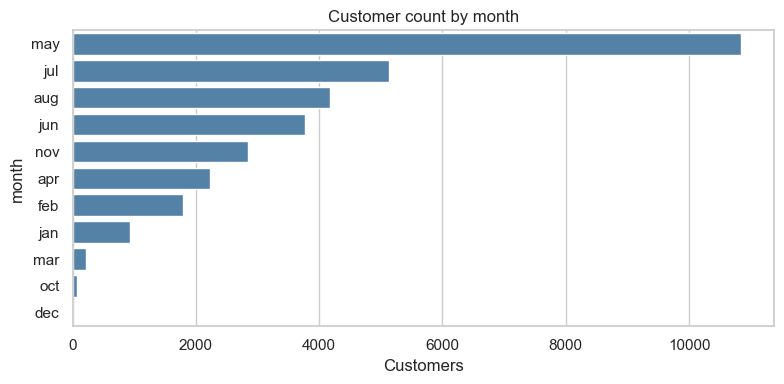

In [36]:
categorical_feature_names = training_eda.select_dtypes(
    include=["object", "category", "string"]
).columns.drop("y", errors="ignore").tolist()
numerical_feature_names = training_eda.select_dtypes(include="number").columns.drop("y").tolist()

figure, plot_axis = plt.subplots(figsize=(5, 3))
sns.countplot(data=training_eda, x="y", order=[0, 1], color="steelblue", ax=plot_axis)
plot_axis.bar_label(plot_axis.containers[0])
plot_axis.set(title="Original training class counts", xlabel="Subscription: 0 = No, 1 = Yes")
plt.tight_layout()
plt.show()

for feature_name in categorical_feature_names:
    figure, plot_axis = plt.subplots(figsize=(8, 4))
    sns.countplot(data=training_eda, y=feature_name,
                  order=training_eda[feature_name].value_counts().index, color="steelblue", ax=plot_axis)
    plot_axis.set(title=f"Customer count by {feature_name}", xlabel="Customers")
    plt.tight_layout()
    plt.show()

### Interpretation

- Only **7.24%** of customers subscribe; the dataset is strongly imbalanced.
- Predicting “no” for everyone already gives about **92.76% accuracy**; accuracy alone does not show success at finding buyers.

## 5. EDA: class 1 counts and subscription rates
Subscriber counts can be large because a category is common. Subscription rate divides subscribers by **all customers in that category**. These are different questions.

,customers,subscribers,subscription_rate
job,,,
student,426,63,0.1479
retired,1146,124,0.1082
management,6458,529,0.0819
unemployed,863,68,0.0788
admin,3579,281,0.0785
self-employed,1119,85,0.0760
technician,5511,403,0.0731
unknown,190,13,0.0684
entrepreneur,1116,71,0.0636


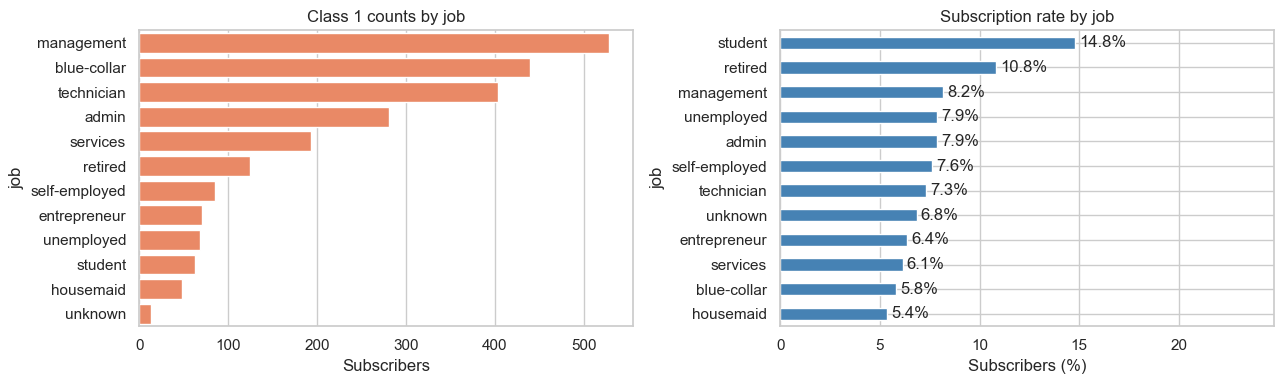

,customers,subscribers,subscription_rate
marital,,,
single,8696,814,0.0936
divorced,3805,325,0.0854
married,19499,1178,0.0604


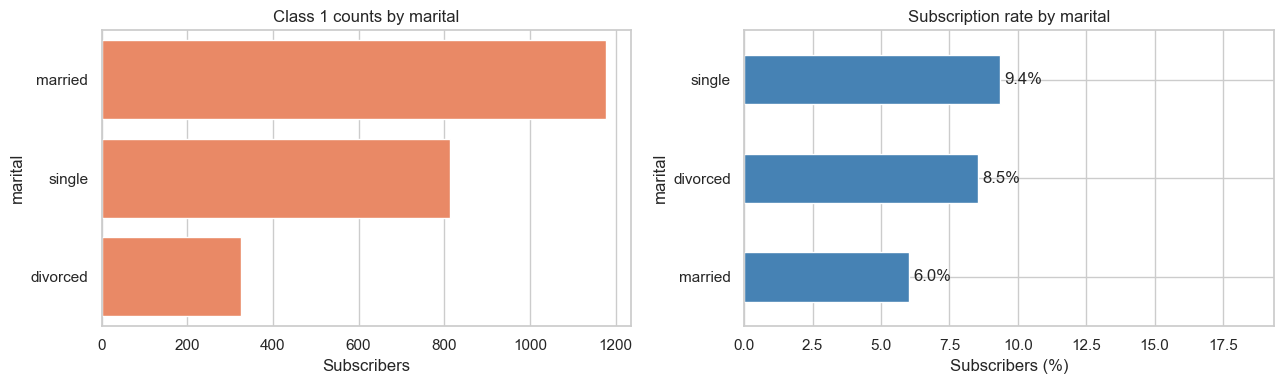

,customers,subscribers,subscription_rate
education,,,
tertiary,8919,803,0.0900
secondary,16809,1155,0.0687
unknown,1206,78,0.0647
primary,5066,281,0.0555


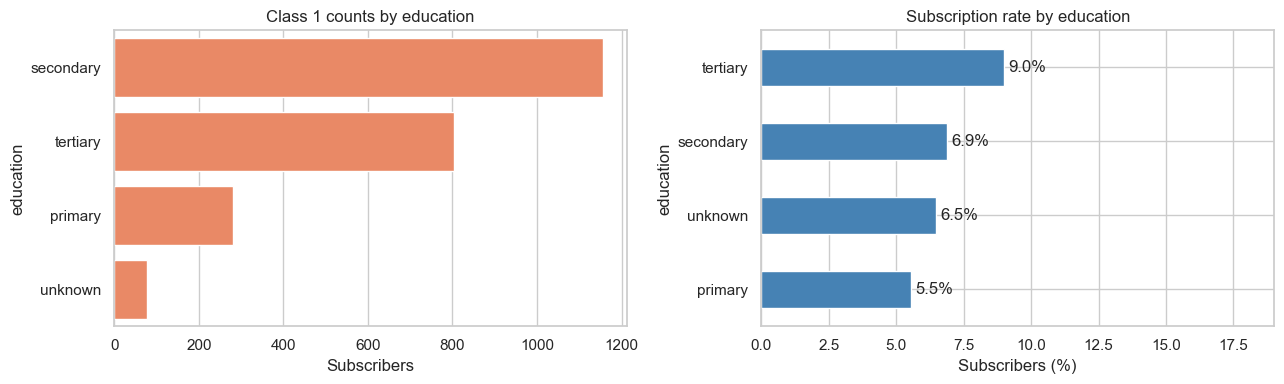

,customers,subscribers,subscription_rate
default,,,
no,31335,2273,0.0725
yes,665,44,0.0662


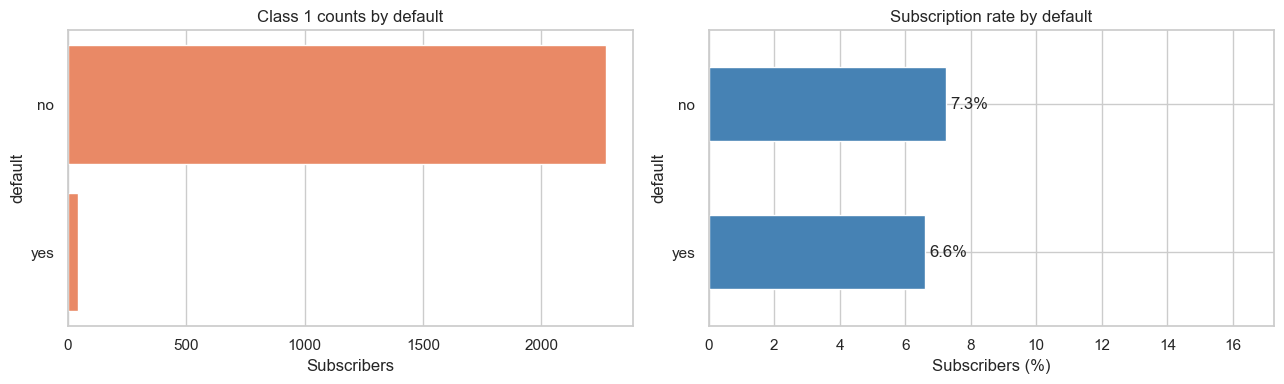

,customers,subscribers,subscription_rate
housing,,,
no,12731,1124,0.0883
yes,19269,1193,0.0619


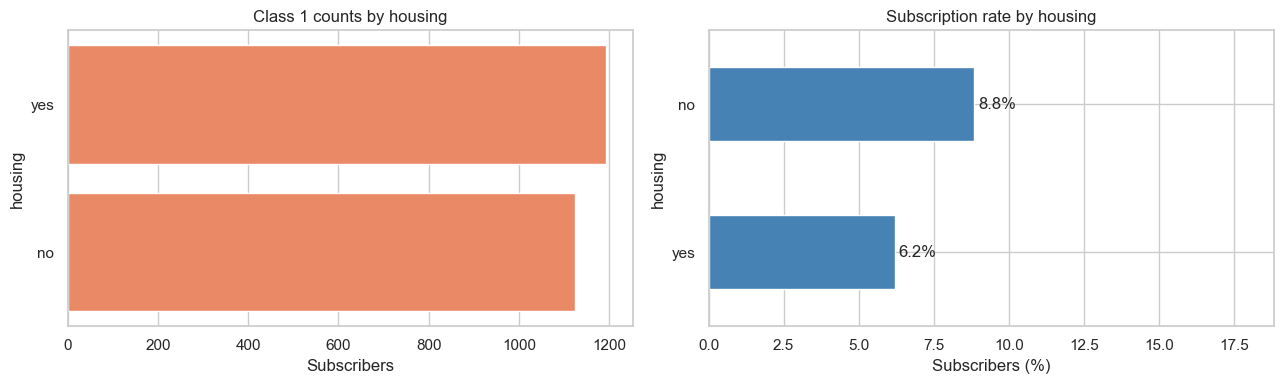

,customers,subscribers,subscription_rate
loan,,,
no,26423,2012,0.0761
yes,5577,305,0.0547


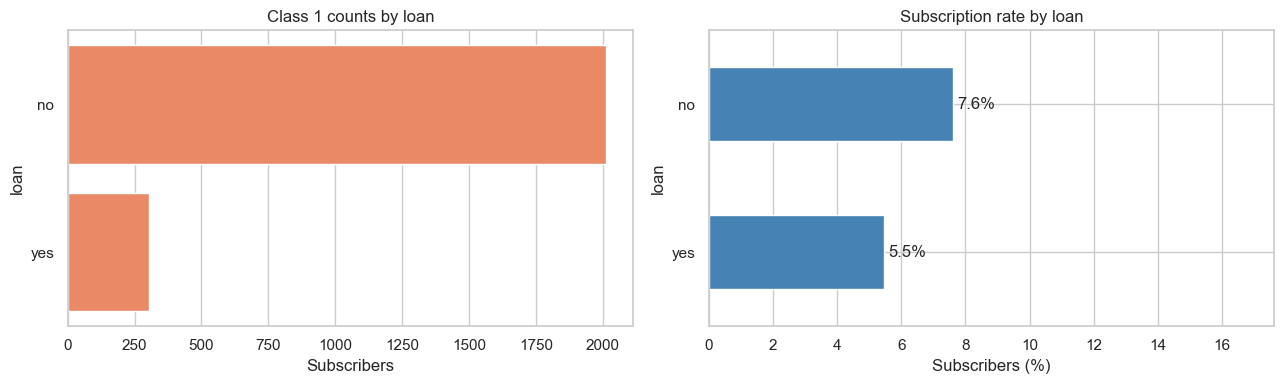

,customers,subscribers,subscription_rate
contact,,,
cellular,19971,1788,0.0895
telephone,1848,129,0.0698
unknown,10181,400,0.0393


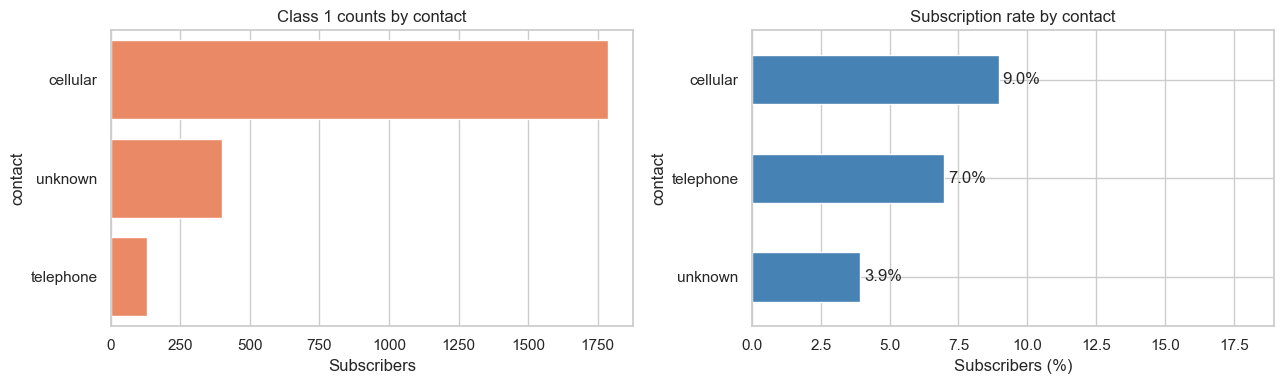

,customers,subscribers,subscription_rate
month,,,
oct,65,42,0.6462
mar,216,101,0.4676
apr,2221,355,0.1598
feb,1792,194,0.1083
jul,5128,318,0.0620
nov,2851,171,0.0600
may,10836,646,0.0596
jun,3769,223,0.0592
aug,4179,237,0.0567


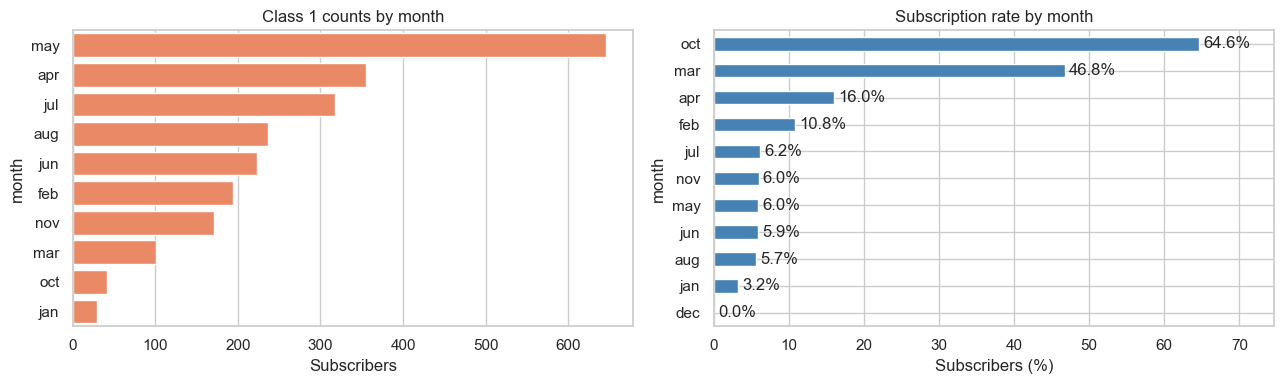

In [37]:
subscribed_customers = training_eda.loc[training_eda["y"] == 1]
category_summaries = {}
for feature_name in categorical_feature_names:
    summary_table = training_eda.groupby(feature_name, dropna=False, observed=True)["y"].agg(
        customers="size", subscribers="sum", subscription_rate="mean"
    ).sort_values("subscription_rate", ascending=False)
    category_summaries[feature_name] = summary_table
    display(summary_table.round(4))
    figure, plot_axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.countplot(data=subscribed_customers, y=feature_name,
                  order=subscribed_customers[feature_name].value_counts().index,
                  color="coral", ax=plot_axes[0])
    plot_axes[0].set(title=f"Class 1 counts by {feature_name}", xlabel="Subscribers")
    subscription_rates = summary_table["subscription_rate"].mul(100)
    subscription_rates.index = subscription_rates.index.map(str)
    subscription_rates.plot.barh(ax=plot_axes[1], color="steelblue")
    plot_axes[1].invert_yaxis()
    plot_axes[1].bar_label(plot_axes[1].containers[0], fmt="%.1f%%", padding=3)
    plot_axes[1].set(title=f"Subscription rate by {feature_name}", xlabel="Subscribers (%)")
    plot_axes[1].set_xlim(0, min(110, max(10, subscription_rates.max() + 10)))
    plt.tight_layout()
    plt.show()

### Interpretation: customer segments

- **Students (14.79%)** and **retired customers (10.82%)** have the highest subscription rates among job categories.
- **Single customers (9.36%)**, **tertiary-educated customers (9.00%)**, and customers **without housing loans (8.83%)** are useful outreach candidates.
- **Cellular contact (8.95%)** outperforms unknown contact (3.93%) in these historical data.
- **October (64.62%; 65 customers)** and **March (46.76%; 216 customers)** have high rates, but small samples and campaign timing limit generalization.
- These are separate, overlapping groups; their rates do not establish the rate of a combined segment.

## 6. EDA: numerical distributions, correlations and age groups

,count,mean,std,min,25%,50%,75%,max
age,32000.0,40.52,9.63,19.0,33.0,39.0,48.0,95.0
balance,32000.0,1273.87,2894.15,-8019.0,54.0,407.0,1323.0,102127.0
day,32000.0,16.04,8.27,1.0,8.0,17.0,21.0,31.0
campaign,32000.0,2.87,3.22,1.0,1.0,2.0,3.0,63.0


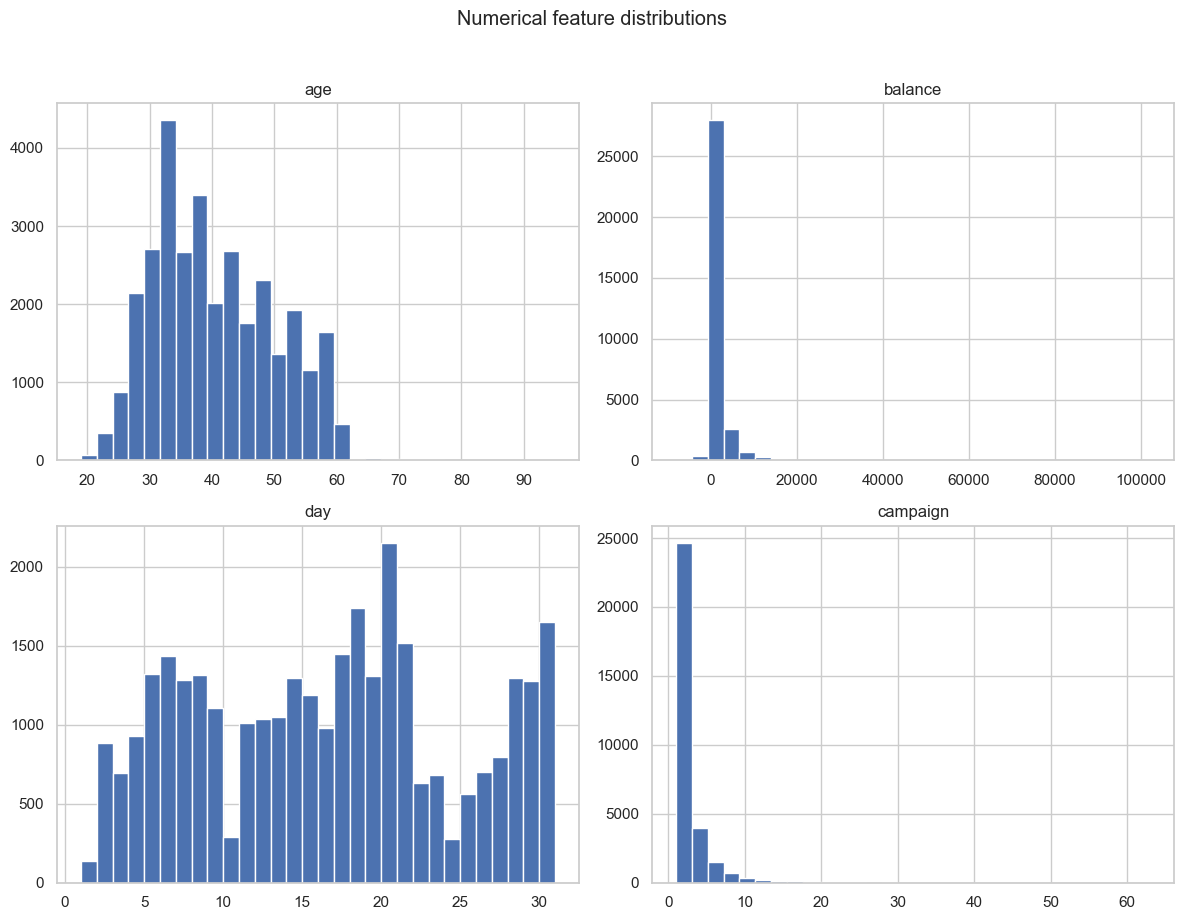

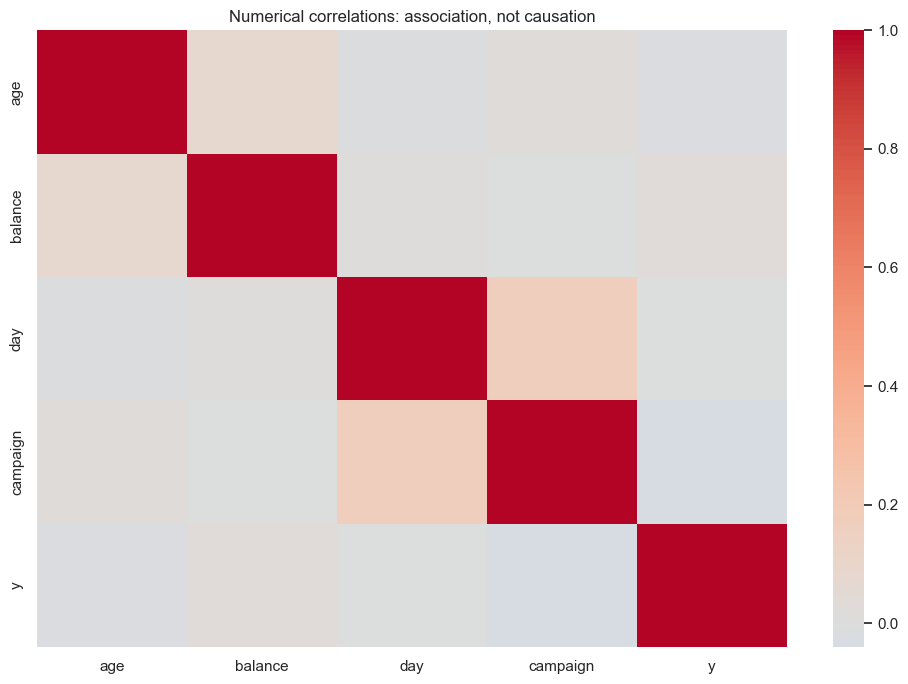

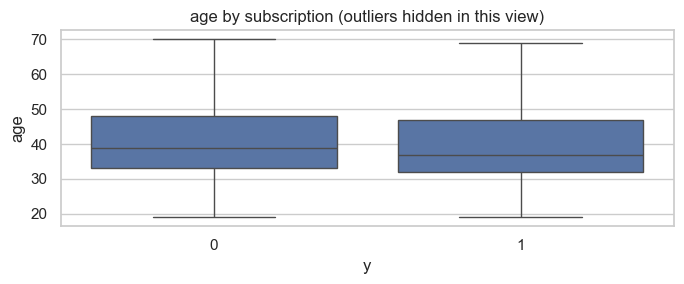

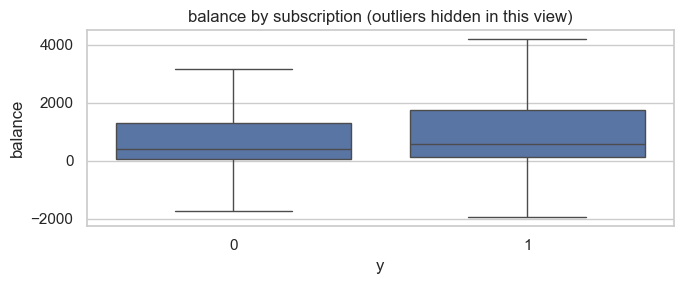

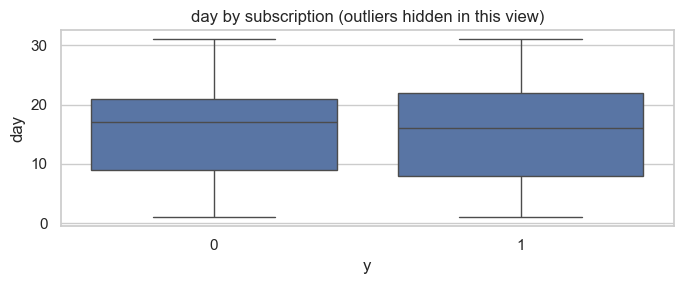

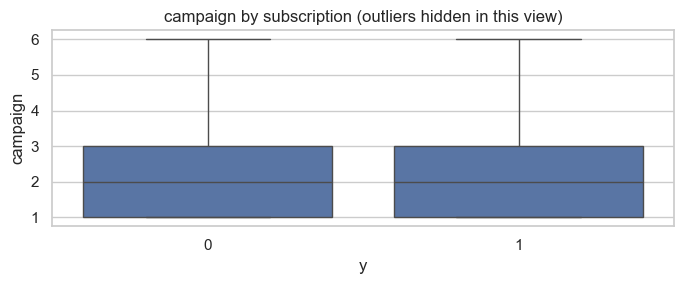

,customers,rate
age,,
Under 30,3439,0.105845
30–39,13127,0.071989
40–49,8761,0.062550
50–59,6080,0.057072
60+,593,0.190556


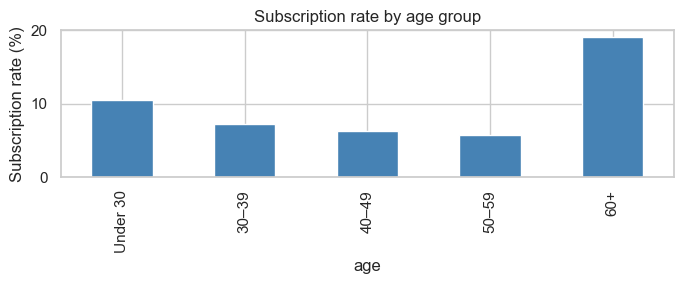

In [38]:
if numerical_feature_names:
    display(training_eda[numerical_feature_names].describe().T.round(2))
    training_eda[numerical_feature_names].hist(figsize=(12, 9), bins=30)
    plt.suptitle("Numerical feature distributions", y=1.02)
    plt.tight_layout()
    plt.show()
    figure, plot_axis = plt.subplots(figsize=(10, 7))
    sns.heatmap(training_eda[numerical_feature_names + ["y"]].corr(), cmap="coolwarm", center=0, ax=plot_axis)
    plot_axis.set_title("Numerical correlations: association, not causation")
    plt.tight_layout()
    plt.show()
    for feature_name in numerical_feature_names:
        figure, plot_axis = plt.subplots(figsize=(7, 3))
        sns.boxplot(data=training_eda, x="y", y=feature_name, showfliers=False, ax=plot_axis)
        plot_axis.set_title(f"{feature_name} by subscription (outliers hidden in this view)")
        plt.tight_layout()
        plt.show()

if "age" in training_eda:
    age_groups = pd.cut(training_eda["age"], bins=[0, 30, 40, 50, 60, np.inf],
                  labels=["Under 30", "30–39", "40–49", "50–59", "60+"], right=False)
    age_group_summary = training_eda.groupby(age_groups, observed=True)["y"].agg(customers="size", rate="mean")
    display(age_group_summary)
    age_group_summary["rate"].mul(100).plot.bar(color="steelblue", figsize=(7, 3))
    plt.ylabel("Subscription rate (%)")
    plt.title("Subscription rate by age group")
    plt.tight_layout()
    plt.show()

### Interpretation: numerical features

- Customers aged **60+ (19.06%; 593 customers)** and **under 30 (10.58%; 3,439 customers)** show higher subscription rates.
- Balance is right-skewed: the mean (**1,273.87**) exceeds the median (**407**).

## 7. Statistical exploration
Chi-square tests explore categorical association with y. Mann–Whitney tests compare numerical distributions. Results do not establish causation; repeated tests and small category counts need care. No columns are deleted solely because of p-values.

In [39]:
statistical_rows = []
for feature_name in categorical_feature_names:
    contingency_table = pd.crosstab(training_eda[feature_name].fillna("missing"), training_eda["y"])
    if contingency_table.shape[0] >= 2 and contingency_table.shape[1] == 2:
        test_statistic, p_value, _, expected_counts = chi2_contingency(contingency_table)
        statistical_rows.append({"feature": feature_name, "test": "chi-square",
                                 "p_value": p_value,
                                 "small_expected_counts": bool((expected_counts < 5).any())})
for feature_name in numerical_feature_names:
    non_subscriber_values = training_eda.loc[training_eda["y"] == 0, feature_name].dropna()
    subscriber_values = training_eda.loc[training_eda["y"] == 1, feature_name].dropna()
    if len(non_subscriber_values) and len(subscriber_values):
        _, p_value = mannwhitneyu(non_subscriber_values, subscriber_values, alternative="two-sided")
        statistical_rows.append({"feature": feature_name, "test": "Mann–Whitney",
                                 "p_value": p_value, "small_expected_counts": False})
statistical_results = pd.DataFrame(statistical_rows)
if not statistical_results.empty:
    display(statistical_results.sort_values("p_value"))

,feature,test,p_value,small_expected_counts
7,month,chi-square,4.793621e-251,True
6,contact,chi-square,8.428413e-56,False
1,marital,chi-square,1.640893e-24,False
9,balance,Mann–Whitney,1.034084e-20,False
4,housing,chi-square,6.175619e-19,False
0,job,chi-square,2.714626e-17,False
11,campaign,Mann–Whitney,1.935430e-15,False
2,education,chi-square,1.549282e-14,False
5,loan,chi-square,2.270521e-08,False
8,age,Mann–Whitney,3.049343e-08,False


### Interpretation

- Statistical association identifies useful patterns; it does **not** prove why customers buy.
- Use sample size, model importance and validation performance alongside significance tests.

## 8. Feature engineering
Month sine/cosine represents the annual cycle. Set `CYCLICAL_MONTH=False` to retain month for one-hot encoding. For pdays, retain a sentinel indicator and treat -1/999 as missing elapsed time; the imputer learns replacement values within each fold. Previous marketing contact is not proof of being a new/existing bank customer.

In [40]:
def prepare_features(customer_data):
    """Apply fixed rules; no statistics or target information are learned here."""
    engineered_features = customer_data.drop(columns=["y", "duration"], errors="ignore").copy()
    if "month" in engineered_features and CYCLICAL_MONTH:
        month_map = {m: i for i, m in enumerate(
            ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], 1)}
        month_numbers = engineered_features["month"].astype(str).str.lower().str[:3].map(month_map)
        # Also accept an already numeric month column.
        numeric_month_values = pd.to_numeric(engineered_features["month"], errors="coerce")
        month_numbers = month_numbers.fillna(numeric_month_values.where(numeric_month_values.between(1, 12)))
        engineered_features["month_sin"] = np.sin(2 * np.pi * (month_numbers - 1) / 12)
        engineered_features["month_cos"] = np.cos(2 * np.pi * (month_numbers - 1) / 12)
        engineered_features = engineered_features.drop(columns="month")
    if "pdays" in engineered_features:
        days_since_previous_contact = pd.to_numeric(engineered_features["pdays"], errors="coerce")
        missing_contact_time = days_since_previous_contact.isin([-1, 999])
        engineered_features["pdays_sentinel"] = missing_contact_time.astype(int)
        engineered_features["pdays"] = days_since_previous_contact.mask(missing_contact_time)
    if "previous" in engineered_features:
        previous_contact_counts = pd.to_numeric(engineered_features["previous"], errors="coerce")
        engineered_features["previously_contacted"] = (previous_contact_counts > 0).astype(int)
    return engineered_features

training_features = prepare_features(training_customers_raw)
test_features = prepare_features(test_customers_raw)
print("Features after engineering:", training_features.columns.tolist())

Features after engineering: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'campaign', 'month_sin', 'month_cos']


### Interpretation

- `month_sin` and `month_cos` represent campaign seasonality; interpret them together as **month**.
- Exclude **call duration** when prioritizing customers before a call because it is unavailable then.

## 9. Preprocessing definition

In [41]:
numerical_column_names = training_features.select_dtypes(include="number").columns.tolist()
categorical_column_names = training_features.select_dtypes(exclude="number").columns.tolist()
numerical_preprocessing = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler())
])
categorical_preprocessing = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
feature_preprocessor = ColumnTransformer([
    ("numeric", numerical_preprocessing, numerical_column_names),
    ("categorical", categorical_preprocessing, categorical_column_names)
])

## 10. Oversampling and plots: training demonstration only
ROS duplicates class 1 examples until class counts are equal. It adds rows, not columns. The arrays in this demonstration are **not used for cross-validation**. Every CV fold will refit its own preprocessing and resampling.

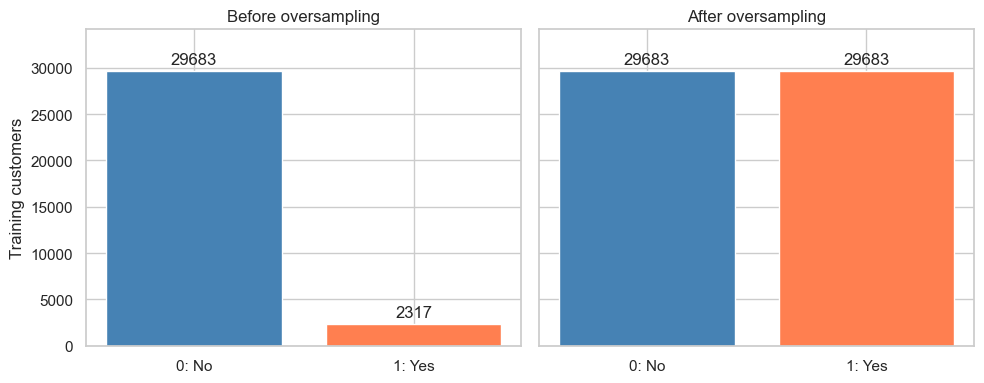

Rows before: 32000 Rows after: 59366


In [42]:
visualization_preprocessor = clone(feature_preprocessor)
processed_training_features = visualization_preprocessor.fit_transform(training_features)
training_oversampler = RandomOverSampler(random_state=RANDOM_STATE)
oversampled_training_features, oversampled_training_labels = training_oversampler.fit_resample(processed_training_features, training_labels)

figure, plot_axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for plot_axis, class_labels, title in zip(plot_axes, [training_labels, oversampled_training_labels],
                            ["Before oversampling", "After oversampling"]):
    counts = pd.Series(np.asarray(class_labels)).value_counts().reindex([0, 1], fill_value=0)
    plot_axis.bar(["0: No", "1: Yes"], counts.values, color=["steelblue", "coral"])
    plot_axis.bar_label(plot_axis.containers[0], padding=3)
    plot_axis.set_title(title)
    plot_axis.margins(y=0.15)
plot_axes[0].set_ylabel("Training customers")
plt.tight_layout()
plt.show()
print("Rows before:", len(training_labels), "Rows after:", len(oversampled_training_labels))

## 11. Metric calculation definition
Precision/recall/F1/support are returned for both classes. Accuracy is overall correctness; balanced accuracy averages class recall. ROC-AUC and average precision use class 1 probabilities and do not use a single classification threshold.

In [43]:
def calculate_metrics(actual_labels, subscription_probabilities, threshold=0.5):
    subscription_probabilities = np.asarray(subscription_probabilities)
    predicted_labels = (subscription_probabilities >= threshold).astype(int)
    metric_scores = {
        "accuracy": accuracy_score(actual_labels, predicted_labels),
        "balanced_accuracy": balanced_accuracy_score(actual_labels, predicted_labels)
    }
    # Ranking metrics require both true classes for ROC-AUC.
    if len(np.unique(actual_labels)) == 2:
        metric_scores["roc_auc"] = roc_auc_score(actual_labels, subscription_probabilities)
        metric_scores["average_precision"] = average_precision_score(actual_labels, subscription_probabilities)
    else:
        metric_scores["roc_auc"] = np.nan
        metric_scores["average_precision"] = np.nan
    class_precision, class_recall, class_f1_scores, class_sample_counts = precision_recall_fscore_support(
        actual_labels, predicted_labels, labels=[0, 1], zero_division=0
    )
    for class_index, class_label in enumerate([0, 1]):
        metric_scores[f"precision_{class_label}"] = class_precision[class_index]
        metric_scores[f"recall_{class_label}"] = class_recall[class_index]
        metric_scores[f"f1_{class_label}"] = class_f1_scores[class_index]
        metric_scores[f"support_{class_label}"] = int(class_sample_counts[class_index])
    return metric_scores


def predict_subscription_probabilities(trained_pipeline, customer_features):
    subscriber_column_index = list(trained_pipeline.classes_).index(1)
    return trained_pipeline.predict_proba(customer_features)[:, subscriber_column_index]

## Sampling strategies and visual comparison
| Method | What changes |
|---|---|
| Original | No resampling |
| Random oversampling | Duplicates minority examples |
| Random undersampling | Removes majority examples at random |
| SMOTE | Interpolates neighboring minority examples |
| ADASYN | Generates more examples near difficult minority regions |
| Tomek links | Removes majority members of nearest-neighbor boundary pairs |
| SMOTE–Tomek | Combines synthetic generation and boundary cleaning |

The following plots illustrate the first two processed feature columns. Every sampling strategy operates on all processed features; only two columns are displayed. These arrays are not passed into cross-validation. Validation folds fit their own preprocessing and sampler. ADASYN may not achieve exact balance, and cleaning methods can change final counts.


In [44]:
sampling_strategies = {
    "Original": "passthrough",
    "Random oversampling": RandomOverSampler(random_state=RANDOM_STATE),
    "Random undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE, k_neighbors=5),
    "ADASYN": ADASYN(random_state=RANDOM_STATE, n_neighbors=5),
    "Tomek links": TomekLinks(sampling_strategy="majority"),
    "SMOTE-Tomek": SMOTETomek(
        random_state=RANDOM_STATE,
        smote=SMOTE(random_state=RANDOM_STATE, k_neighbors=5),
        tomek=TomekLinks(sampling_strategy="majority")
    )
}


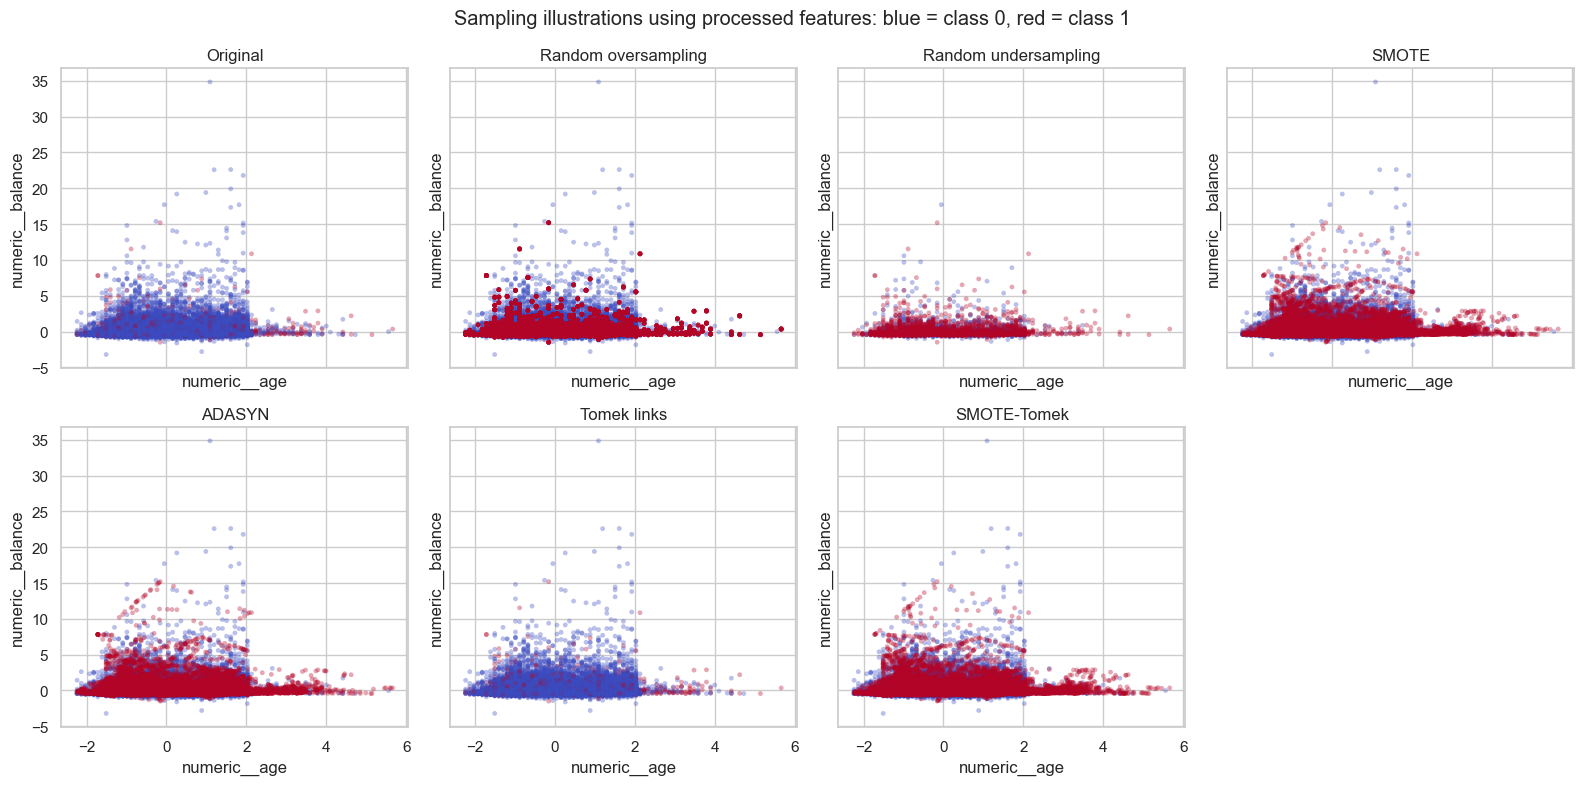

,class_0,class_1,status
method,,,
Original,29683,2317,ok
Random oversampling,29683,29683,ok
Random undersampling,2317,2317,ok
SMOTE,29683,29683,ok
ADASYN,29683,29998,ok
Tomek links,28725,2317,ok
SMOTE-Tomek,29477,29683,ok


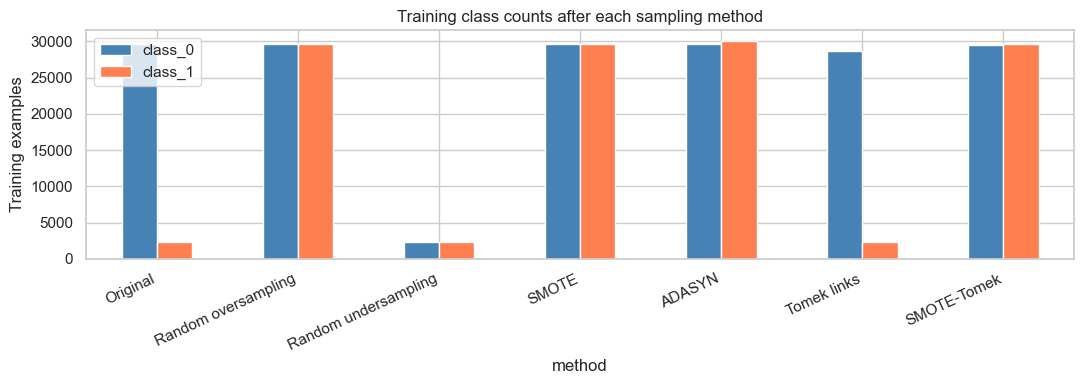

In [45]:
sampling_plot_preprocessor = clone(feature_preprocessor)
encoded_plot_features = sampling_plot_preprocessor.fit_transform(training_features)
processed_feature_names = sampling_plot_preprocessor.get_feature_names_out()
if encoded_plot_features.shape[1] < 2:
    raise ValueError("At least two processed feature columns are needed for the sampling illustration.")

def plot_processed_features(customer_features, subscription_labels, plot_axis, title):
    plot_axis.scatter(customer_features[:, 0], customer_features[:, 1],
                      c=np.asarray(subscription_labels), cmap="coolwarm",
                      vmin=0, vmax=1, alpha=0.35, s=12, edgecolors="none")
    plot_axis.set(xlabel=processed_feature_names[0], ylabel=processed_feature_names[1], title=title)

figure, plot_axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
sampling_plot_counts = []
for plot_axis, (sampling_name, sampling_method) in zip(plot_axes.flat, sampling_strategies.items()):
    try:
        if isinstance(sampling_method, str):
            sampled_features, sampled_labels = encoded_plot_features, training_labels
        else:
            sampled_features, sampled_labels = clone(sampling_method).fit_resample(
                encoded_plot_features, training_labels)
        class_counts = pd.Series(np.asarray(sampled_labels)).value_counts()
        sampling_plot_counts.append({"method": sampling_name,
                                     "class_0": int(class_counts.get(0, 0)),
                                     "class_1": int(class_counts.get(1, 0)), "status": "ok"})
        plot_processed_features(sampled_features, sampled_labels, plot_axis, sampling_name)
    except ValueError as sampling_error:
        plot_axis.set_title(sampling_name + " — failed")
        sampling_plot_counts.append({"method": sampling_name, "status": str(sampling_error)})
plot_axes.flat[-1].axis("off")
figure.suptitle("Sampling illustrations using processed features: blue = class 0, red = class 1")
plt.tight_layout()
plt.show()
sampling_count_results = pd.DataFrame(sampling_plot_counts).set_index("method")
display(sampling_count_results)
valid_sampling_counts = sampling_count_results.loc[
    sampling_count_results["status"] == "ok", ["class_0", "class_1"]]
if not valid_sampling_counts.empty:
    plot_axis = valid_sampling_counts.plot.bar(figsize=(11, 4), color=["steelblue", "coral"])
    plot_axis.set(title="Training class counts after each sampling method", ylabel="Training examples")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
sampling_count_results.to_csv(RESULTS_DIRECTORY / "sampling_illustration_counts.csv")


### Interpretation

- Oversampling balances training classes; it does not create new evidence about real customers.
- Validation and test sets keep their original class proportions for realistic evaluation.

## 12. Models and pipeline definition
Compare original processed features and random oversampling for each classifier. Compare the additional sampling methods with the same Logistic Regression configuration. All preprocessing and sampling are fitted inside training folds.


In [46]:
model_definitions = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=160, min_samples_leaf=4,
                                             n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150, learning_rate=0.06, max_leaf_nodes=20,
        l2_regularization=1.0, random_state=RANDOM_STATE)
}

def build_model_pipeline(classifier, sampling_method="passthrough"):
    """Fit preprocessing, optional sampling and the classifier within each training fold."""
    sampling_step = sampling_method if isinstance(sampling_method, str) else clone(sampling_method)
    return ImbPipeline([
        ("preprocessor", clone(feature_preprocessor)),
        ("oversampler", sampling_step),
        ("model", clone(classifier))
    ])

candidate_pipelines = {
    "Majority baseline": build_model_pipeline(DummyClassifier(strategy="most_frequent"))
}
for model_name, classifier in model_definitions.items():
    candidate_pipelines[model_name + " | Original"] = build_model_pipeline(classifier)
    candidate_pipelines[model_name + " | ROS"] = build_model_pipeline(
        classifier, sampling_method=RandomOverSampler(random_state=RANDOM_STATE))
candidate_pipelines["Logistic Regression | RUS"] = build_model_pipeline(
    model_definitions["Logistic Regression"],
    sampling_method=RandomUnderSampler(random_state=RANDOM_STATE))
print("Candidate pipelines:", len(candidate_pipelines))

# Controlled sampling comparison: identical classifier and processed feature columns.
for sampling_name, sampling_method in sampling_strategies.items():
    candidate_name = "Logistic Regression | Sampling | " + sampling_name
    candidate_pipelines[candidate_name] = build_model_pipeline(
        model_definitions["Logistic Regression"], sampling_method=sampling_method)

# Balanced weights are alternatives to resampling, not combined with full ROS.
candidate_pipelines["Logistic Regression | Balanced weights"] = build_model_pipeline(
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
candidate_pipelines["Random Forest | Balanced weights"] = build_model_pipeline(
    RandomForestClassifier(n_estimators=160, min_samples_leaf=4, n_jobs=-1,
                           class_weight="balanced_subsample", random_state=RANDOM_STATE))
print("Total candidate pipelines:", len(candidate_pipelines))


Candidate pipelines: 8
Total candidate pipelines: 17


### L1, L2 and weakly regularized logistic regression
These three additional variants use balanced class weights, preprocessing and original processed features, with no resampling. The numerical scaler is already inside the preprocessor; do not add another scaler outside it.

- **L1:** can shrink some coefficients to zero; `solver="liblinear"` supports this penalty.
- **L2:** shrinks coefficients without selecting an exact sparse subset.
- **Weak L2:** uses `C=100000`, approximating very weak regularization. It is not exactly an unpenalized fit.
- Smaller C means stronger regularization. Search logarithmically spaced values from 0.001 to 1000, plus `fit_intercept=True/False`.

**Nested validation:** each of the five outer folds runs a five-fold GridSearchCV on its training portion. The untouched outer fold provides the score used in the main comparison. This avoids evaluating parameters on the folds used to choose them. The same test set is retained. Grid-search candidates add 550 inner validation fits with default settings, plus final refits, so they take longer. Best parameters printed after full-training fitting can differ from those selected in individual outer folds.

In [47]:
logistic_variant_definitions = {
    "Logistic L1 | Nested grid": LogisticRegression(
        penalty="l1", solver="liblinear", max_iter=3000,
        class_weight="balanced", random_state=RANDOM_STATE),
    "Logistic L2 | Nested grid": LogisticRegression(
        penalty="l2", solver="liblinear", max_iter=3000,
        class_weight="balanced", random_state=RANDOM_STATE),
    "Logistic weak L2 | Nested grid": LogisticRegression(
        penalty="l2", solver="lbfgs", C=100000, max_iter=3000,
        class_weight="balanced", random_state=RANDOM_STATE)
}
logistic_parameter_grids = {}
for variant_name, variant_classifier in logistic_variant_definitions.items():
    C_values = [100000.0] if "weak L2" in variant_name else LOGISTIC_C_VALUES
    logistic_parameter_grids[variant_name] = {
        "model__C": C_values,
        "model__fit_intercept": [True, False]
    }
    variant_pipeline = build_model_pipeline(variant_classifier)
    candidate_pipelines[variant_name] = GridSearchCV(
        estimator=variant_pipeline,
        param_grid=logistic_parameter_grids[variant_name],
        scoring=LOGISTIC_GRID_SCORING,
        cv=StratifiedKFold(n_splits=LOGISTIC_GRID_FOLDS, shuffle=True,
                          random_state=RANDOM_STATE),
        n_jobs=1, refit=True, error_score="raise", verbose=2
    )
print("Total candidates including logistic variants:", len(candidate_pipelines))


Total candidates including logistic variants: 20


## 13. Five-fold evaluation definition

In [48]:
def evaluate_five_folds(model_pipeline, model_name, customer_features, subscription_labels):
    cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    label_array = np.asarray(subscription_labels)
    fold_metric_rows = []
    out_of_fold_probabilities = np.full(len(label_array), np.nan)
    for fold_number, (training_indices, validation_indices) in enumerate(cross_validator.split(customer_features, label_array), start=1):
        fold_model_pipeline = clone(model_pipeline)
        fold_model_pipeline.fit(customer_features.iloc[training_indices], label_array[training_indices])
        subscription_probabilities = predict_subscription_probabilities(fold_model_pipeline, customer_features.iloc[validation_indices])
        out_of_fold_probabilities[validation_indices] = subscription_probabilities
        fold_metric_rows.append({"model": model_name, "fold": fold_number,
                          **calculate_metrics(label_array[validation_indices], subscription_probabilities)})
    return pd.DataFrame(fold_metric_rows), out_of_fold_probabilities

## 14. Evaluate and compare all candidates
Each row of `all_fold_results` is a validation round. `cross_validation_summary` averages those five rounds. Rank by average precision, so majority accuracy alone cannot win. Failures are reported instead of hidden.

Evaluating: Majority baseline
Evaluating: Logistic Regression | Original
Evaluating: Logistic Regression | ROS
Evaluating: Random Forest | Original
Evaluating: Random Forest | ROS
Evaluating: Hist Gradient Boosting | Original
Evaluating: Hist Gradient Boosting | ROS
Evaluating: Logistic Regression | RUS
Evaluating: Logistic Regression | Sampling | Original
Evaluating: Logistic Regression | Sampling | Random oversampling
Evaluating: Logistic Regression | Sampling | Random undersampling
Evaluating: Logistic Regression | Sampling | SMOTE
Evaluating: Logistic Regression | Sampling | ADASYN
Evaluating: Logistic Regression | Sampling | Tomek links
Evaluating: Logistic Regression | Sampling | SMOTE-Tomek
Evaluating: Logistic Regression | Balanced weights
Evaluating: Random Forest | Balanced weights
Evaluating: Logistic L1 | Nested grid
Fitting 2 folds for each of 6 candidates, totalling 12 fits
[CV] END ...........model__C=0.01, model__fit_intercept=True; total time=   0.0s
[CV] END .........

,accuracy,balanced_accuracy,roc_auc,average_precision,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,accuracy_std,meets_81_percent_at_0.5
model,,,,,,,,,,,,
Hist Gradient Boosting | Original,0.9283,0.5167,0.7079,0.2464,0.9298,0.9980,0.9627,0.5911,0.0354,0.0667,0.0008,True
Hist Gradient Boosting | ROS,0.7610,0.6531,0.7067,0.2433,0.9548,0.7793,0.8581,0.1571,0.5270,0.2419,0.0068,False
Random Forest | Original,0.9276,0.5058,0.6978,0.2288,0.9284,0.9990,0.9624,0.5007,0.0125,0.0244,0.0004,True
Random Forest | Balanced weights,0.9068,0.6026,0.6982,0.2176,0.9422,0.9584,0.9502,0.3162,0.2469,0.2772,0.0028,True
Random Forest | ROS,0.8954,0.6088,0.6929,0.2108,0.9433,0.9440,0.9437,0.2757,0.2736,0.2746,0.0030,True
Logistic Regression | Sampling | Tomek links,0.9276,0.5000,0.6543,0.1753,0.9276,1.0000,0.9624,0.0000,0.0000,0.0000,0.0001,True
Logistic Regression | Original,0.9276,0.5000,0.6546,0.1743,0.9276,1.0000,0.9624,0.0000,0.0000,0.0000,0.0001,True
Logistic Regression | Sampling | Original,0.9276,0.5000,0.6546,0.1743,0.9276,1.0000,0.9624,0.0000,0.0000,0.0000,0.0001,True
Logistic Regression | Sampling | SMOTE,0.6121,0.6057,0.6513,0.1656,0.9514,0.6132,0.7457,0.1077,0.5982,0.1825,0.0071,False


,model,fold,accuracy,balanced_accuracy,roc_auc,average_precision,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Majority baseline,1,0.9277,0.5000,0.5000,0.0723,0.9277,1.0000,0.9625,5937,0.0000,0.0000,0.0000,463
1,Majority baseline,2,0.9277,0.5000,0.5000,0.0723,0.9277,1.0000,0.9625,5937,0.0000,0.0000,0.0000,463
2,Majority baseline,3,0.9277,0.5000,0.5000,0.0723,0.9277,1.0000,0.9625,5937,0.0000,0.0000,0.0000,463
3,Majority baseline,4,0.9275,0.5000,0.5000,0.0725,0.9275,1.0000,0.9624,5936,0.0000,0.0000,0.0000,464
4,Majority baseline,5,0.9275,0.5000,0.5000,0.0725,0.9275,1.0000,0.9624,5936,0.0000,0.0000,0.0000,464
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,Logistic weak L2 | Nested grid,1,0.6159,0.5988,0.6452,0.1514,0.9496,0.6188,0.7493,5937,0.1059,0.5788,0.1790,463
96,Logistic weak L2 | Nested grid,2,0.6147,0.6081,0.6594,0.1497,0.9518,0.6158,0.7478,5937,0.1086,0.6004,0.1840,463
97,Logistic weak L2 | Nested grid,3,0.6228,0.6155,0.6524,0.1650,0.9532,0.6241,0.7543,5937,0.1118,0.6069,0.1888,463
98,Logistic weak L2 | Nested grid,4,0.6086,0.6132,0.6581,0.1601,0.9532,0.6078,0.7423,5936,0.1098,0.6185,0.1864,464


Class 0: average scores


,precision_0,recall_0,f1_0
model,,,
Hist Gradient Boosting | Original,0.9298,0.9980,0.9627
Hist Gradient Boosting | ROS,0.9548,0.7793,0.8581
Random Forest | Original,0.9284,0.9990,0.9624
Random Forest | Balanced weights,0.9422,0.9584,0.9502
Random Forest | ROS,0.9433,0.9440,0.9437
Logistic Regression | Sampling | Tomek links,0.9276,1.0000,0.9624
Logistic Regression | Original,0.9276,1.0000,0.9624
Logistic Regression | Sampling | Original,0.9276,1.0000,0.9624
Logistic Regression | Sampling | SMOTE,0.9514,0.6132,0.7457


Class 1: average scores


,precision_1,recall_1,f1_1
model,,,
Hist Gradient Boosting | Original,0.5911,0.0354,0.0667
Hist Gradient Boosting | ROS,0.1571,0.5270,0.2419
Random Forest | Original,0.5007,0.0125,0.0244
Random Forest | Balanced weights,0.3162,0.2469,0.2772
Random Forest | ROS,0.2757,0.2736,0.2746
Logistic Regression | Sampling | Tomek links,0.0000,0.0000,0.0000
Logistic Regression | Original,0.0000,0.0000,0.0000
Logistic Regression | Sampling | Original,0.0000,0.0000,0.0000
Logistic Regression | Sampling | SMOTE,0.1077,0.5982,0.1825


Selected by average precision: Hist Gradient Boosting | Original


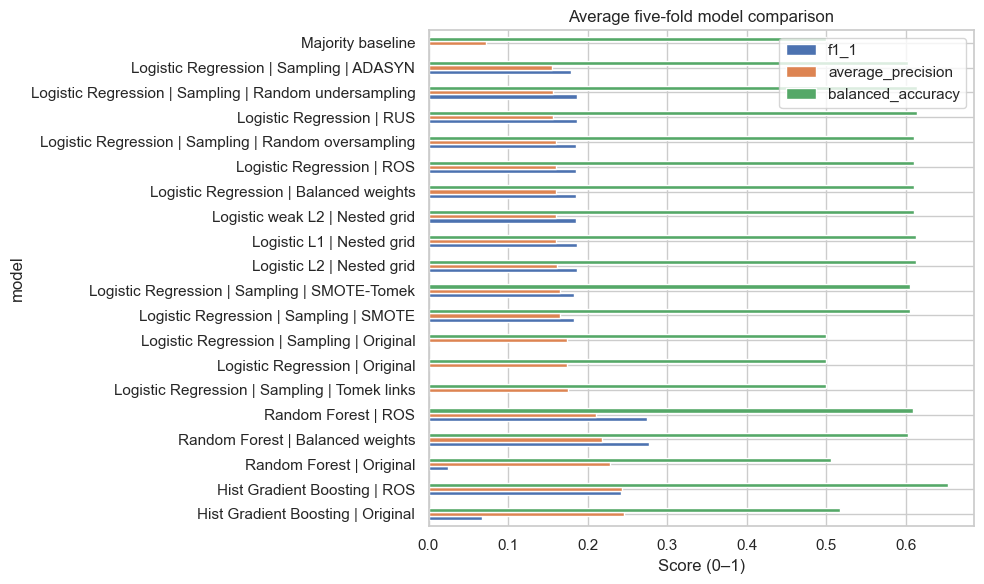

In [49]:
model_fold_tables = []
out_of_fold_probabilities_by_model = {}
failed_model_details = []
for model_name, model_pipeline in candidate_pipelines.items():
    print("Evaluating:", model_name, flush=True)
    try:
        model_fold_results, subscription_probabilities = evaluate_five_folds(model_pipeline, model_name, training_features, training_labels)
        model_fold_tables.append(model_fold_results)
        out_of_fold_probabilities_by_model[model_name] = subscription_probabilities
    except ValueError as evaluation_error:
        failed_model_details.append({"model": model_name, "error": str(evaluation_error)})
        print("FAILED:", evaluation_error)
if not model_fold_tables:
    raise RuntimeError("All models failed; inspect the errors above.")
all_fold_results = pd.concat(model_fold_tables, ignore_index=True)
metric_column_names = [column_name for column_name in all_fold_results if column_name not in ["model", "fold", "support_0", "support_1"]]
cross_validation_summary = all_fold_results.groupby("model")[metric_column_names].mean()
cross_validation_summary["accuracy_std"] = all_fold_results.groupby("model")["accuracy"].std()
cross_validation_summary["meets_81_percent_at_0.5"] = cross_validation_summary["accuracy"] >= MIN_ACCURACY
cross_validation_summary = cross_validation_summary.sort_values("average_precision", ascending=False)
display(cross_validation_summary.round(4))
display(all_fold_results.round(4))
for class_label in [0, 1]:
    print(f"Class {class_label}: average scores")
    display(cross_validation_summary[[f"precision_{class_label}", f"recall_{class_label}", f"f1_{class_label}"]].round(4))
if failed_model_details:
    display(pd.DataFrame(failed_model_details))
cross_validation_summary.to_csv(RESULTS_DIRECTORY / "five_fold_average.csv")
all_fold_results.to_csv(RESULTS_DIRECTORY / "all_fold_results.csv", index=False)

# Select using training validation only, not test results.
candidate_model_summary = cross_validation_summary.drop(index="Majority baseline", errors="ignore")
if candidate_model_summary.empty:
    raise RuntimeError("Only the baseline succeeded; resolve model errors first.")
selected_model_name = candidate_model_summary["average_precision"].idxmax()
selected_model_pipeline = clone(candidate_pipelines[selected_model_name])
print("Selected by average precision:", selected_model_name)
cross_validation_summary[["f1_1", "average_precision", "balanced_accuracy"]].plot.barh(figsize=(10, 6))
plt.title("Average five-fold model comparison")
plt.xlabel("Score (0–1)")
plt.tight_layout()
plt.show()

### Interpretation: 5-fold success metric

- **Hist Gradient Boosting | Original:** mean 5-fold accuracy **92.83%**, standard deviation approximately **0.08 percentage points**, at threshold **0.50**.
- The **81% accuracy goal is achieved**, but the majority baseline also achieves **92.76%**.
- At threshold 0.50, this model finds only **3.54%** of subscribers on average; class 1 F1 is **6.67%**.
- The notebook selects this model by **average precision** for ranking; class 1 F1 is then improved through threshold tuning.

### Compare L1, L2 and weak L2 results
These are outer-fold scores, not the inner search's best scores. Compare both classes' precision/recall/F1 and ranking performance with the other models. Full-training best parameters are printed in the training section and saved in `logistic_best_parameters.csv`.

,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,roc_auc,average_precision,accuracy_std
model,,,,,,,,,,,
Logistic L1 | Nested grid,0.6127,0.6123,0.9529,0.6127,0.7458,0.1098,0.6120,0.1862,0.6580,0.1602,0.0077
Logistic L2 | Nested grid,0.6158,0.6129,0.9529,0.6163,0.7485,0.1103,0.6094,0.1868,0.6578,0.1610,0.0065
Logistic weak L2 | Nested grid,0.6135,0.6104,0.9524,0.6141,0.7467,0.1093,0.6068,0.1852,0.6572,0.1602,0.0067


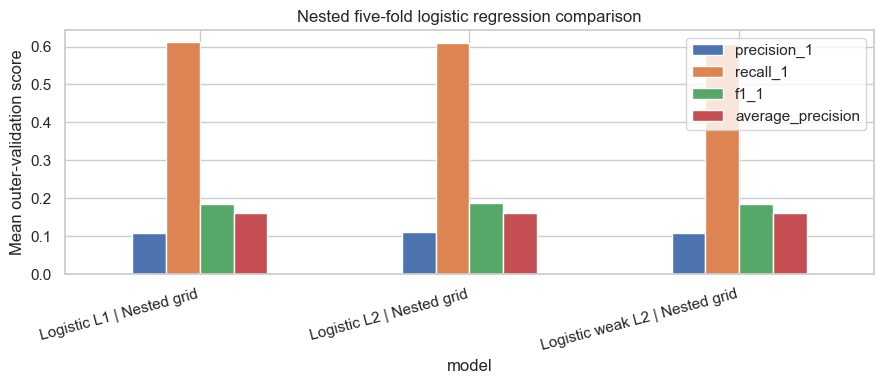

In [50]:
logistic_variant_names = [variant_name for variant_name in logistic_variant_definitions
                          if variant_name in cross_validation_summary.index]
if logistic_variant_names:
    logistic_variant_results = cross_validation_summary.loc[logistic_variant_names, [
        "accuracy", "balanced_accuracy", "precision_0", "recall_0", "f1_0",
        "precision_1", "recall_1", "f1_1", "roc_auc", "average_precision", "accuracy_std"
    ]]
    display(logistic_variant_results.round(4))
    logistic_variant_results.to_csv(RESULTS_DIRECTORY / "logistic_variant_comparison.csv")
    logistic_variant_results[["precision_1", "recall_1", "f1_1", "average_precision"]].plot.bar(
        figsize=(9, 4))
    plt.title("Nested five-fold logistic regression comparison")
    plt.ylabel("Mean outer-validation score")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()


### Sampling-method results on identical validation folds
Scores are means across five natural-prevalence validation folds at threshold 0.5. Compare class 1 precision, recall and F1, average precision and balanced accuracy. Positive changes are improvements relative to the same logistic-regression model without resampling. Failures are saved separately. Higher precision from the 2-D illustration is not a performance result; only validation/test metrics assess prediction.

,sampling_method,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,average_precision,roc_auc,f1_1_change,AP_change
0,Tomek links,0.9276,0.5000,0.9276,1.0000,0.9624,0.0000,0.0000,0.0000,0.1753,0.6543,0.0000,0.0010
1,Original,0.9276,0.5000,0.9276,1.0000,0.9624,0.0000,0.0000,0.0000,0.1743,0.6546,0.0000,0.0000
2,SMOTE,0.6121,0.6057,0.9514,0.6132,0.7457,0.1077,0.5982,0.1825,0.1656,0.6513,0.1825,-0.0086
3,SMOTE-Tomek,0.6084,0.6059,0.9516,0.6088,0.7425,0.1074,0.6029,0.1823,0.1653,0.6512,0.1823,-0.0090
4,Random oversampling,0.6151,0.6107,0.9524,0.6158,0.7479,0.1095,0.6055,0.1855,0.1600,0.6571,0.1855,-0.0143
5,Random undersampling,0.6125,0.6137,0.9532,0.6123,0.7456,0.1102,0.6150,0.1869,0.1559,0.6556,0.1869,-0.0183
6,ADASYN,0.5855,0.6031,0.9520,0.5826,0.7228,0.1044,0.6236,0.1789,0.1551,0.6490,0.1789,-0.0191


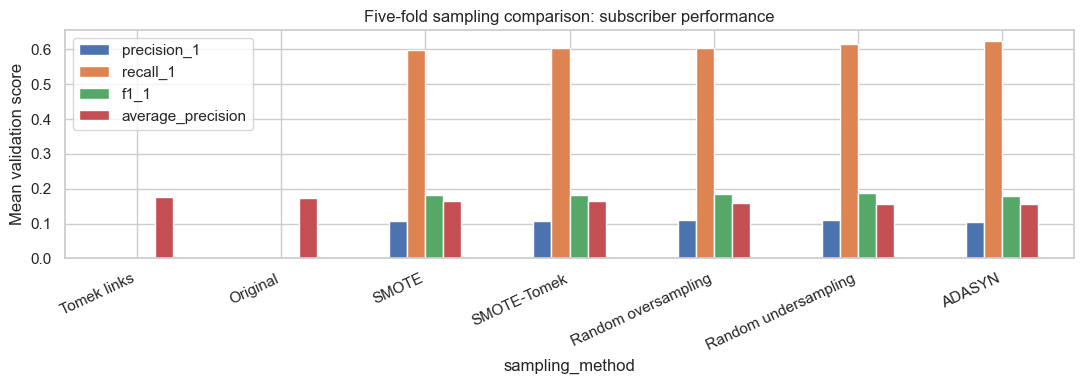

In [51]:
sampling_comparison_rows = []
sampling_reference_name = "Logistic Regression | Sampling | Original"
if sampling_reference_name in cross_validation_summary.index:
    sampling_reference_scores = cross_validation_summary.loc[sampling_reference_name]
    for candidate_name, candidate_scores in cross_validation_summary.iterrows():
        prefix = "Logistic Regression | Sampling | "
        if not candidate_name.startswith(prefix):
            continue
        sampling_comparison_rows.append({
            "sampling_method": candidate_name[len(prefix):],
            "accuracy": candidate_scores["accuracy"],
            "balanced_accuracy": candidate_scores["balanced_accuracy"],
            "precision_0": candidate_scores["precision_0"],
            "recall_0": candidate_scores["recall_0"],
            "f1_0": candidate_scores["f1_0"],
            "precision_1": candidate_scores["precision_1"],
            "recall_1": candidate_scores["recall_1"],
            "f1_1": candidate_scores["f1_1"],
            "average_precision": candidate_scores["average_precision"],
            "roc_auc": candidate_scores["roc_auc"],
            "f1_1_change": candidate_scores["f1_1"] - sampling_reference_scores["f1_1"],
            "AP_change": candidate_scores["average_precision"] - sampling_reference_scores["average_precision"]
        })
sampling_comparison_results = pd.DataFrame(sampling_comparison_rows)
if not sampling_comparison_results.empty:
    sampling_comparison_results = sampling_comparison_results.sort_values(
        "average_precision", ascending=False)
    display(sampling_comparison_results.round(4))
    sampling_comparison_results.set_index("sampling_method")[[
        "precision_1", "recall_1", "f1_1", "average_precision"
    ]].plot.bar(figsize=(11, 4))
    plt.title("Five-fold sampling comparison: subscriber performance")
    plt.ylabel("Mean validation score")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    sampling_comparison_results.to_csv(RESULTS_DIRECTORY / "sampling_comparison_results.csv", index=False)
if failed_model_details:
    pd.DataFrame(failed_model_details).to_csv(RESULTS_DIRECTORY / "failed_methods.csv", index=False)


### Interpretation

- Sampling changes the trade-off between finding subscribers and making false-positive calls.
- At threshold 0.50, **Random Forest with balanced weights** has the highest mean class 1 F1 (**27.72%**) in the saved comparison.

## 15. Optional hyperparameter tuning
Set `RUN_TUNING=True` in Step 1. Search the selected model's parameters and sampling choice inside five-fold CV. This includes no oversampling, partial ROS when valid, and full ROS. Tuning on the same folds makes subsequent OOF scores optimistic; final test results are the independent check. Nested CV is needed for an unbiased tuned CV estimate.

In [52]:
if RUN_TUNING and not isinstance(selected_model_pipeline, GridSearchCV):
    selected_classifier = selected_model_pipeline.named_steps["model"]
    if isinstance(selected_classifier, LogisticRegression):
        parameter_search_space = {"model__C": [0.05, 0.1, 0.5, 1, 5, 10]}
    elif isinstance(selected_classifier, RandomForestClassifier):
        parameter_search_space = {
            "model__n_estimators": [160, 250, 350],
            "model__max_depth": [None, 8, 12, 20],
            "model__min_samples_leaf": [2, 4, 6],
            "model__max_features": ["sqrt", 0.5]
        }
    else:
        parameter_search_space = {
            "model__learning_rate": [0.03, 0.06, 0.1],
            "model__max_iter": [100, 150, 250],
            "model__max_leaf_nodes": [10, 20, 31],
            "model__l2_regularization": [0.0, 1.0, 5.0]
        }
    sampling_options = ["passthrough", RandomOverSampler(random_state=RANDOM_STATE)]
    training_class_counts = training_labels.value_counts()
    minority_ratio = training_class_counts.min() / training_class_counts.max()
    for sampling_ratio in [0.25, 0.50]:
        if sampling_ratio > minority_ratio:
            sampling_options.append(RandomOverSampler(
                sampling_strategy=sampling_ratio, random_state=RANDOM_STATE))
    parameter_search_space["oversampler"] = sampling_options
    hyperparameter_search = RandomizedSearchCV(
        selected_model_pipeline, parameter_search_space, n_iter=SEARCH_ITERATIONS,
        scoring="average_precision",
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=1, random_state=RANDOM_STATE, verbose=1, error_score="raise"
    )
    hyperparameter_search.fit(training_features, training_labels)
    print("Best parameters:", hyperparameter_search.best_params_)
    selected_model_pipeline = clone(hyperparameter_search.best_estimator_)
    selected_model_name = selected_model_name + " | Tuned"
    tuned_fold_results, tuned_out_of_fold_probabilities = evaluate_five_folds(
        selected_model_pipeline, selected_model_name, training_features, training_labels)
    out_of_fold_probabilities_by_model[selected_model_name] = tuned_out_of_fold_probabilities
    display(tuned_fold_results.round(4))
else:
    print("Additional random search skipped. Nested logistic candidates already perform grid search.")

Additional random search skipped. Nested logistic candidates already perform grid search.


## 16. Threshold tuning using OOF training probabilities
Select the best class 1 F1 while meeting 81% accuracy, or choose the highest recall among thresholds meeting 40% precision and 81% accuracy. If constraints fail, report that explicitly. This does not guarantee the same scores on new customers. These OOF scores are development results after threshold selection, not independent final scores.

Selected threshold: 0.14
Constraints met on OOF development data: True


,OOF development score
accuracy,0.9068
balanced_accuracy,0.6251
roc_auc,0.7070
average_precision,0.2432
precision_0,0.9455
recall_0,0.9545
f1_0,0.9500
support_0,29683.0000
precision_1,0.3364
recall_1,0.2956


,accuracy,balanced_accuracy,roc_auc,average_precision,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1,threshold
13,0.9068,0.6251,0.707,0.2432,0.9455,0.9545,0.9500,29683,0.3364,0.2956,0.3147,2317,0.14
17,0.9160,0.6163,0.707,0.2432,0.9440,0.9668,0.9553,29683,0.3845,0.2659,0.3144,2317,0.18
16,0.9145,0.6173,0.707,0.2432,0.9442,0.9648,0.9544,29683,0.3743,0.2697,0.3135,2317,0.17
14,0.9099,0.6212,0.707,0.2432,0.9449,0.9588,0.9518,29683,0.3493,0.2836,0.3130,2317,0.15
15,0.9124,0.6188,0.707,0.2432,0.9445,0.9622,0.9532,29683,0.3623,0.2754,0.3129,2317,0.16
12,0.9010,0.6277,0.707,0.2432,0.9461,0.9473,0.9467,29683,0.3134,0.3082,0.3108,2317,0.13
18,0.9167,0.6131,0.707,0.2432,0.9436,0.9681,0.9557,29683,0.3871,0.2581,0.3097,2317,0.19
19,0.9181,0.6116,0.707,0.2432,0.9433,0.9699,0.9564,29683,0.3969,0.2533,0.3093,2317,0.20
20,0.9189,0.6107,0.707,0.2432,0.9432,0.9711,0.9569,29683,0.4031,0.2503,0.3088,2317,0.21
21,0.9197,0.6087,0.707,0.2432,0.9429,0.9723,0.9574,29683,0.4086,0.2451,0.3064,2317,0.22


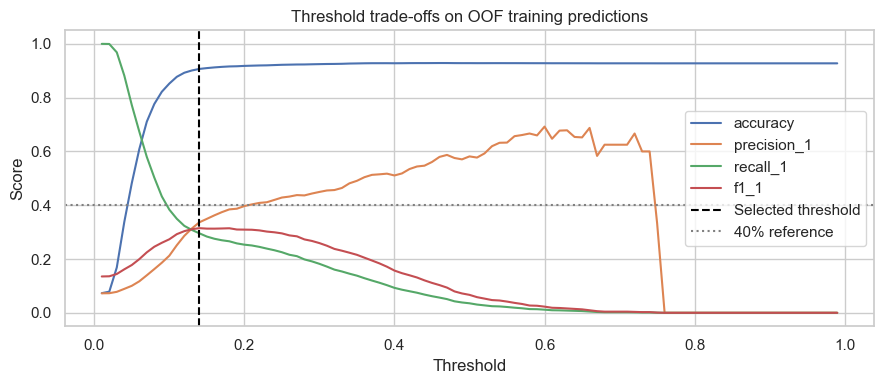

In [53]:
threshold_metric_rows = []
for threshold in np.arange(0.01, 1.00, 0.01):
    threshold_metrics = calculate_metrics(training_labels, out_of_fold_probabilities_by_model[selected_model_name], threshold)
    threshold_metrics["threshold"] = threshold
    threshold_metric_rows.append(threshold_metrics)
threshold_results = pd.DataFrame(threshold_metric_rows)
eligible_threshold_results = threshold_results.loc[threshold_results["accuracy"] >= MIN_ACCURACY]
if THRESHOLD_GOAL == "precision":
    eligible_threshold_results = eligible_threshold_results.loc[(eligible_threshold_results["precision_1"] >= TARGET_PRECISION) & (eligible_threshold_results["recall_1"] > 0)]
    threshold_ranking_columns = ["recall_1", "f1_1"]
elif THRESHOLD_GOAL == "f1":
    threshold_ranking_columns = ["f1_1", "precision_1"]
else:
    raise ValueError("THRESHOLD_GOAL must be f1 or precision.")
threshold_constraints_met = not eligible_threshold_results.empty
if eligible_threshold_results.empty:
    print("Requested constraints were not achieved. Falling back to highest training OOF F1.")
    eligible_threshold_results = threshold_results
    threshold_ranking_columns = ["f1_1", "precision_1"]
selected_threshold_metrics = eligible_threshold_results.sort_values(threshold_ranking_columns, ascending=False).iloc[0]
selected_threshold = float(selected_threshold_metrics["threshold"])
print("Selected threshold:", round(selected_threshold, 2))
print("Constraints met on OOF development data:", threshold_constraints_met)
display(selected_threshold_metrics.to_frame("OOF development score").round(4))
display(threshold_results.sort_values("f1_1", ascending=False).head(10).round(4))
figure, plot_axis = plt.subplots(figsize=(9, 4))
for metric_name in ["accuracy", "precision_1", "recall_1", "f1_1"]:
    plot_axis.plot(threshold_results["threshold"], threshold_results[metric_name], label=metric_name)
plot_axis.axvline(selected_threshold, color="black", linestyle="--", label="Selected threshold")
plot_axis.axhline(0.40, color="gray", linestyle=":", label="40% reference")
plot_axis.set(xlabel="Threshold", ylabel="Score", title="Threshold trade-offs on OOF training predictions")
plot_axis.legend()
plt.tight_layout()
plt.show()
threshold_results.to_csv(RESULTS_DIRECTORY / "threshold_results.csv", index=False)

### Interpretation: threshold tuning

- Lowering the selected model's threshold to **0.14** gives OOF class 1 F1 **31.47%** and accuracy **90.68%**.
- These are pooled development scores used to choose the threshold; they are not an independent tuned 5-fold estimate.

## 17. Train on the full training set
All successful candidates are fitted and kept in a dictionary. The final selected configuration is fitted separately. Test data is not oversampled or used for fitting.

In [54]:
trained_model_pipelines = {}
logistic_search_summaries = []
for model_name in out_of_fold_probabilities_by_model:
    if model_name in candidate_pipelines:
        print("Training:", model_name, flush=True)
        fitted_candidate = clone(candidate_pipelines[model_name]).fit(training_features, training_labels)
        if isinstance(fitted_candidate, GridSearchCV):
            logistic_search_summaries.append({
                "model": model_name,
                "best_inner_cv_score": fitted_candidate.best_score_,
                "best_C": fitted_candidate.best_params_["model__C"],
                "fit_intercept": fitted_candidate.best_params_["model__fit_intercept"]
            })
            trained_model_pipelines[model_name] = fitted_candidate.best_estimator_
        else:
            trained_model_pipelines[model_name] = fitted_candidate
fitted_selected_candidate = clone(selected_model_pipeline).fit(training_features, training_labels)
final_model_pipeline = (fitted_selected_candidate.best_estimator_
                        if isinstance(fitted_selected_candidate, GridSearchCV)
                        else fitted_selected_candidate)
if logistic_search_summaries:
    logistic_grid_search_summary = pd.DataFrame(logistic_search_summaries)
    display(logistic_grid_search_summary.round(4))
    logistic_grid_search_summary.to_csv(RESULTS_DIRECTORY / "logistic_best_parameters.csv", index=False)
print("Final fitted model:", selected_model_name)
print("Processed feature count:", len(final_model_pipeline.named_steps["preprocessor"].get_feature_names_out()))


Training: Majority baseline
Training: Logistic Regression | Original
Training: Logistic Regression | ROS
Training: Random Forest | Original
Training: Random Forest | ROS
Training: Hist Gradient Boosting | Original
Training: Hist Gradient Boosting | ROS
Training: Logistic Regression | RUS
Training: Logistic Regression | Sampling | Original
Training: Logistic Regression | Sampling | Random oversampling
Training: Logistic Regression | Sampling | Random undersampling
Training: Logistic Regression | Sampling | SMOTE
Training: Logistic Regression | Sampling | ADASYN
Training: Logistic Regression | Sampling | Tomek links
Training: Logistic Regression | Sampling | SMOTE-Tomek
Training: Logistic Regression | Balanced weights
Training: Random Forest | Balanced weights
Training: Logistic L1 | Nested grid
Fitting 2 folds for each of 6 candidates, totalling 12 fits
[CV] END ...........model__C=0.01, model__fit_intercept=True; total time=   0.1s
[CV] END ...........model__C=0.01, model__fit_intercep

,model,best_inner_cv_score,best_C,fit_intercept
0,Logistic L1 | Nested grid,0.1857,0.10,True
1,Logistic L2 | Nested grid,0.1877,0.01,False
2,Logistic weak L2 | Nested grid,0.1853,100000.00,False


Final fitted model: Hist Gradient Boosting | Original
Processed feature count: 34


## 18. Final test evaluation: both classes, confusion matrix, ROC and PR

accuracy                0.9116
balanced_accuracy       0.6403
roc_auc                 0.7335
average_precision       0.2686
precision_0             0.9477
recall_0                0.9576
f1_0                    0.9526
support_0            7421.0000
precision_1             0.3725
recall_1                0.3230
f1_1                    0.3460
support_1             579.0000
Name: Hist Gradient Boosting | Original, dtype: float64

              precision    recall  f1-score   support

      No (0)     0.9477    0.9576    0.9526      7421
     Yes (1)     0.3725    0.3230    0.3460       579

    accuracy                         0.9116      8000
   macro avg     0.6601    0.6403    0.6493      8000
weighted avg     0.9061    0.9116    0.9087      8000



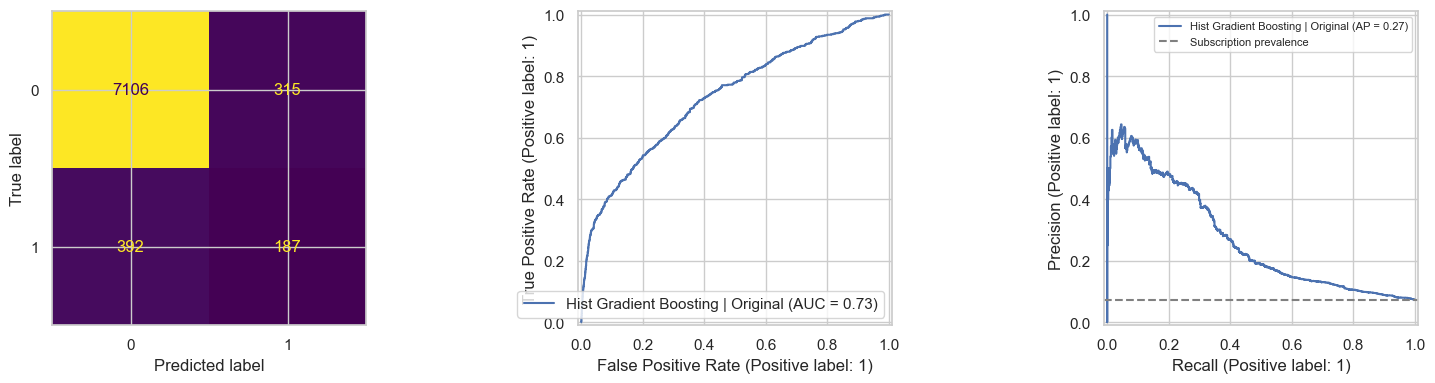

Majority-only test accuracy: 92.76%
Selected model meets 81% test accuracy: True
Selected model reaches 40% test precision: False
Selected model reaches 40% test F1: False


326

In [55]:
test_probabilities = predict_subscription_probabilities(final_model_pipeline, test_features)
test_predictions = (test_probabilities >= selected_threshold).astype(int)
test_metric_scores = pd.Series(calculate_metrics(test_labels, test_probabilities, selected_threshold), name=selected_model_name)
display(test_metric_scores.round(4))
test_classification_report = classification_report(test_labels, test_predictions, labels=[0, 1],
                               target_names=["No (0)", "Yes (1)"], digits=4, zero_division=0)
print(test_classification_report)
figure, plot_axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(test_labels, test_predictions, labels=[0, 1],
                                        ax=plot_axes[0], colorbar=False)
RocCurveDisplay.from_predictions(test_labels, test_probabilities, ax=plot_axes[1], name=selected_model_name)
PrecisionRecallDisplay.from_predictions(test_labels, test_probabilities, ax=plot_axes[2], name=selected_model_name)
plot_axes[2].axhline(test_labels.mean(), color="gray", linestyle="--", label="Subscription prevalence")
plot_axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Majority-only test accuracy:", f"{accuracy_score(test_labels, np.full(len(test_labels), training_labels.mode()[0])):.2%}")
print("Selected model meets 81% test accuracy:", test_metric_scores["accuracy"] >= MIN_ACCURACY)
print("Selected model reaches 40% test precision:", test_metric_scores["precision_1"] >= 0.40)
print("Selected model reaches 40% test F1:", test_metric_scores["f1_1"] >= 0.40)
test_metric_scores.to_csv(RESULTS_DIRECTORY / "selected_model_test_metrics.csv")
(RESULTS_DIRECTORY / "classification_report.txt").write_text(test_classification_report)

### Interpretation: independent test results

- At threshold **0.14**, test accuracy is **91.16%**, class 1 F1 **34.60%**, precision **37.25%**, and recall **32.30%**.
- The model identifies about one-third of actual subscribers; most predicted subscribers still do not buy.
- Test accuracy is below the majority baseline (**92.76%**), but the baseline identifies no subscribers.

## 19. Call prioritization: top 10% lift
Lift compares subscription rate among the highest-scored customers against overall subscription rate. This evaluates ranking, not the selected threshold. Do not interpret scores as calibrated probabilities without checking calibration, especially after resampling.

In [56]:
top_customer_count = max(1, int(np.ceil(0.10 * len(test_labels))))
top_customer_indices = np.argsort(-test_probabilities, kind="stable")[:top_customer_count]
top_subscription_rate = np.asarray(test_labels)[top_customer_indices].mean()
overall_subscription_rate = test_labels.mean()
top_lift = top_subscription_rate / overall_subscription_rate
print("Customers in top 10%:", top_customer_count)
print("Overall subscription rate:", f"{overall_subscription_rate:.2%}")
print("Top 10% subscription rate:", f"{top_subscription_rate:.2%}")
print("Top 10% lift:", round(top_lift, 2))

Customers in top 10%: 800
Overall subscription rate: 7.24%
Top 10% subscription rate: 28.25%
Top 10% lift: 3.9


### Interpretation: whom to call first

- Prioritize the **top 10% by model score**: subscription rate **28.25%**, versus **7.24%** overall, giving **3.90× lift** on the test set.
- Use the score to rank new customers; the observed 28.25% rate is not a guaranteed future conversion rate.

## 20. Interpretability with original input features
Permutation importance measures the loss in average precision after shuffling a feature. Use training data and score with five-fold CV so the test set does not guide feature changes. Features are related associations, not causes. Correlated features can share importance.

,mean_CV_AP_decrease
month_sin,0.124021
contact,0.088238
day,0.072961
month_cos,0.040750
housing,0.028163
age,0.006897
balance,0.006582
campaign,0.003470
loan,0.002834
marital,0.002571


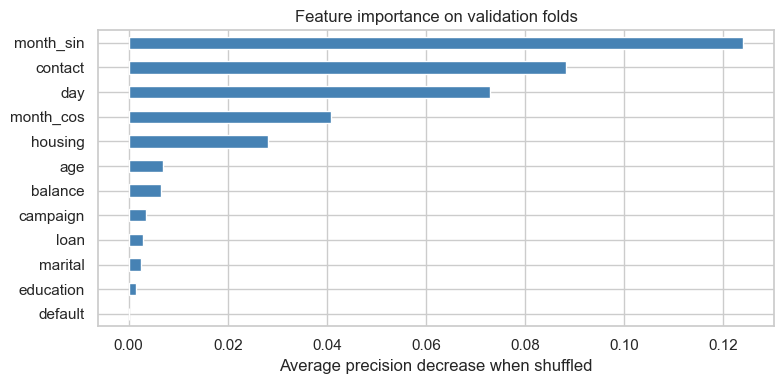

In [57]:
fold_feature_importances = []
importance_cross_validator = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
for training_indices, validation_indices in importance_cross_validator.split(training_features, training_labels):
    importance_model_pipeline = clone(selected_model_pipeline).fit(
        training_features.iloc[training_indices], training_labels.iloc[training_indices])
    permutation_results = permutation_importance(
        importance_model_pipeline, training_features.iloc[validation_indices], training_labels.iloc[validation_indices],
        scoring="average_precision", n_repeats=2, random_state=RANDOM_STATE, n_jobs=1)
    fold_feature_importances.append(permutation_results.importances_mean)
feature_importance = pd.Series(np.mean(fold_feature_importances, axis=0), index=training_features.columns)
feature_importance = feature_importance.sort_values(ascending=False)
display(feature_importance.head(15).to_frame("mean_CV_AP_decrease"))
feature_importance.head(12).sort_values().plot.barh(figsize=(8, 4), color="steelblue")
plt.xlabel("Average precision decrease when shuffled")
plt.title("Feature importance on validation folds")
plt.tight_layout()
plt.show()
feature_importance.to_csv(RESULTS_DIRECTORY / "feature_importance.csv")

### Interpretation: features to focus on

- The strongest predictive signals are **campaign month, contact type, day of month, and housing-loan status**.
- Investigate campaign timing and contact-channel quality first; use housing status to understand customer needs.
- Month's sine/cosine columns are two representations of one feature, not two separate business drivers.
- Permutation importance shows predictive usefulness, not direction or causation; timing may reflect historical campaign effects.

## 21. Error analysis using OOF training predictions
Inspect false positives and false negatives without using test errors to redesign the model. This follows the article's diagnostic idea. The selected threshold has already been optimized on OOF data, so these diagnostics are exploratory.

outcome
True negative     28332
False negative     1632
False positive     1351
True positive       685
Name: count, dtype: int64

False positive


,count,mean,std,min,25%,50%,75%,max
age,1351.0,39.567728,12.927936,19.0,30.0,36.0,48.0,94.0
balance,1351.0,2097.888231,4364.924338,-8019.0,233.5,867.0,2466.0,102127.0
day,1351.0,16.225019,9.791061,1.0,7.0,16.0,26.0,31.0
campaign,1351.0,2.018505,1.907594,1.0,1.0,1.0,2.0,23.0


False negative


,count,mean,std,min,25%,50%,75%,max
age,1632.0,39.477328,9.491135,20.0,32.00,38.0,46.0,69.0
balance,1632.0,1323.791054,2667.398290,-3058.0,81.75,486.5,1437.0,45248.0
day,1632.0,15.072304,7.711834,1.0,8.00,15.0,20.0,31.0
campaign,1632.0,2.666667,2.562842,1.0,1.00,2.0,3.0,32.0


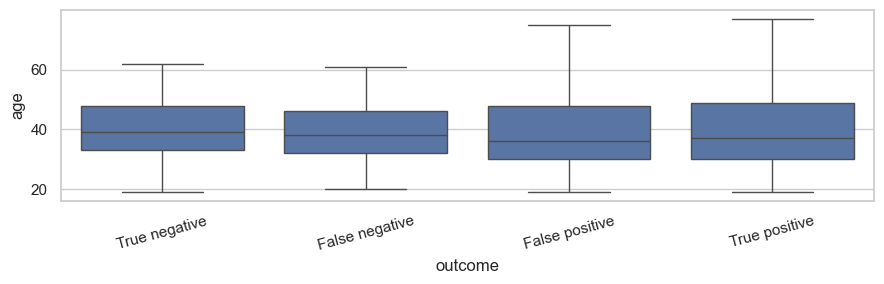

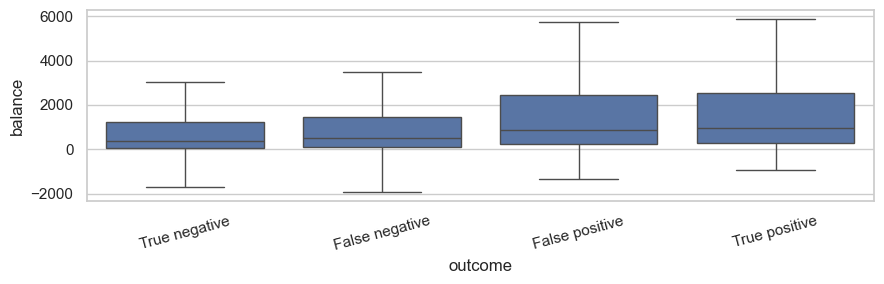

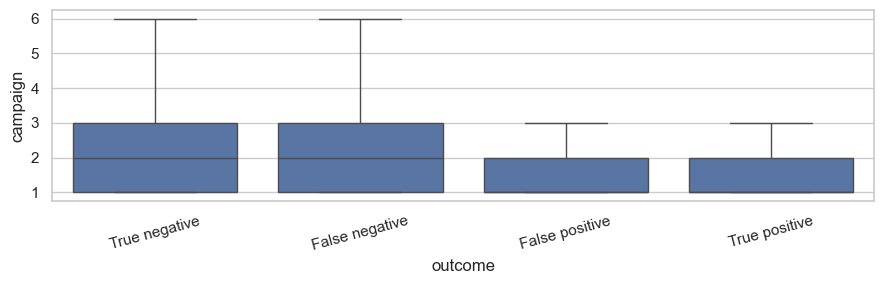

In [58]:
training_error_analysis = training_customers_raw.copy()
training_error_analysis["y"] = np.asarray(training_labels)
training_error_analysis["probability"] = out_of_fold_probabilities_by_model[selected_model_name]
training_error_analysis["prediction"] = (training_error_analysis["probability"] >= selected_threshold).astype(int)
training_error_analysis["outcome"] = np.select(
    [(training_error_analysis["y"] == 1) & (training_error_analysis["prediction"] == 1),
     (training_error_analysis["y"] == 0) & (training_error_analysis["prediction"] == 1),
     (training_error_analysis["y"] == 1) & (training_error_analysis["prediction"] == 0)],
    ["True positive", "False positive", "False negative"], default="True negative")
display(training_error_analysis["outcome"].value_counts())
for prediction_outcome in ["False positive", "False negative"]:
    print(prediction_outcome)
    if numerical_feature_names:
        display(training_error_analysis.loc[training_error_analysis["outcome"] == prediction_outcome, numerical_feature_names].describe().T)
for feature_name in [column_name for column_name in ["age", "balance", "campaign"] if column_name in training_error_analysis]:
    figure, plot_axis = plt.subplots(figsize=(9, 3))
    sns.boxplot(data=training_error_analysis, x="outcome", y=feature_name, showfliers=False, ax=plot_axis)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

### Interpretation

- OOF errors include **1,632 missed subscribers** and **1,351 false positives** at threshold 0.14.
- Improving subscriber detection remains necessary despite meeting the accuracy target.

## 22. Previously contacted versus not previously contacted
Use `previous > 0` for prior marketing-contact history. This is **not** bank-customer tenure. Evaluate the same selected model in subgroups; do not fit tiny separate models automatically.

In [59]:
if "previous" in test_customers_raw:
    previous_contact_counts = pd.to_numeric(test_customers_raw["previous"], errors="coerce")
    contact_history_metric_rows = []
    contact_history_groups = {"No previous marketing contact": previous_contact_counts.eq(0),
              "Previous marketing contact": previous_contact_counts.gt(0)}
    for contact_history_group_name, subgroup_mask in contact_history_groups.items():
        subgroup_mask = subgroup_mask.to_numpy()
        if subgroup_mask.sum():
            contact_history_metric_rows.append({"group": contact_history_group_name, "customers": int(subgroup_mask.sum()),
                **calculate_metrics(np.asarray(test_labels)[subgroup_mask], test_probabilities[subgroup_mask], selected_threshold)})
    contact_history_results = pd.DataFrame(contact_history_metric_rows)
    display(contact_history_results.round(4))
    contact_history_results.to_csv(RESULTS_DIRECTORY / "contact_history_subgroups.csv", index=False)
else:
    print("No previous column: subgroup analysis skipped.")

No previous column: subgroup analysis skipped.


### Interpretation

- This dataset has no `previous` column, so prior marketing-contact segments cannot be evaluated.

## 23. Save the final pipeline and conclusion
The saved pipeline expects **engineered features**. Apply `prepare_features()` with the same configuration before predicting future CSV rows. Keep this notebook alongside the model. Pickle/joblib files should be loaded only from trusted sources.

Write your project conclusion from the printed results: compare against majority accuracy, describe class 1 precision/recall/F1 and lift, state whether the targets were achieved, and report limitations. Do not promise 40% precision or F1 if the independent test results do not achieve it.

In [60]:
joblib.dump(final_model_pipeline, RESULTS_DIRECTORY / "subscription_pipeline.joblib")
summary_table = {
    "selected_model": selected_model_name,
    "threshold": selected_threshold,
    "threshold_goal": THRESHOLD_GOAL,
    "OOF_threshold_constraints_met": threshold_constraints_met,
    "test_metrics": {metric_name: float(metric_value) for metric_name, metric_value in test_metric_scores.items()},
    "top_10_percent_lift": float(top_lift),
    "duration_included": False,
    "cyclical_month": CYCLICAL_MONTH,
    "input_features": training_features.columns.tolist(),
    "top_predictive_features": feature_importance.head(5).index.tolist(),
    "random_state": RANDOM_STATE
}
(RESULTS_DIRECTORY / "model_summary.json").write_text(json.dumps(summary_table, indent=2))
print("Outputs saved in:", RESULTS_DIRECTORY.resolve())
print(json.dumps(summary_table, indent=2))

# Example for later inference (uncomment after supplying future customer rows):
# future_data = pd.read_csv("future_customers.csv", sep=None, engine="python")
# future_X = prepare_features(future_data)
# future_probabilities = positive_probabilities(best_pipeline, future_X)
# future_predictions = (future_probabilities >= best_threshold).astype(int)

Outputs saved in: C:\Users\anagha\Apziva\ApzivaP2_\Ap2_notebooks\bank_results
{
  "selected_model": "Hist Gradient Boosting | Original",
  "threshold": 0.14,
  "threshold_goal": "f1",
  "OOF_threshold_constraints_met": true,
  "test_metrics": {
    "accuracy": 0.911625,
    "balanced_accuracy": 0.6402617647394233,
    "roc_auc": 0.7334914525110672,
    "average_precision": 0.26858043008089894,
    "precision_0": 0.9477193918378234,
    "recall_0": 0.9575528904460315,
    "f1_0": 0.9526107647965681,
    "support_0": 7421.0,
    "precision_1": 0.37250996015936255,
    "recall_1": 0.3229706390328152,
    "f1_1": 0.3459759481961147,
    "support_1": 579.0
  },
  "top_10_percent_lift": 3.9032815198618307,
  "duration_included": false,
  "cyclical_month": true,
  "input_features": [
    "age",
    "job",
    "marital",
    "education",
    "default",
    "balance",
    "housing",
    "loan",
    "contact",
    "day",
    "campaign",
    "month_sin",
    "month_cos"
  ],
  "top_predictive_fea

## Final business conclusion

- **Prediction goal:** A pre-call model predicts term-deposit subscription without using call duration.
- **Accuracy target met:** **92.83% mean accuracy across 5 folds** at threshold 0.50; the majority baseline is **92.76%**.
- **Subscriber detection:** After threshold tuning, independent test class 1 F1 is **34.60%**, with **32.30% recall**.
- **First priority:** Call the highest-scored **10%** of customers; saved test results show **3.90× lift**.
- **Promising segments:** Customers aged **60+**, younger customers **under 30**, students and retirees; assess overlapping segments before combining rules.
- **Feature focus:** Campaign **month**, **contact channel**, **day**, and **housing-loan status**.
- **What makes customers buy?** These data show associations, not motivations or causal effects; test campaign timing and channel changes prospectively.
- **Next step:** Validate performance on later campaigns and track subscriber conversions and cost per successful call.